# Part 2: Reliability-Gated MACE

**Paper:** Montori et al., "A Metadata-Assisted Cascading Ensemble Classification Framework for Automatic Annotation of Open IoT Data", IEEE Internet of Things Journal, 10(15), 2023

Part 1 showed that MACE's gain comes entirely from combining stream names with numerical features on ThingSpeak but that MACE trusts the name for every stream through a fixed, hard filter. When names are missing, unseen in training or differently formatted, the cascade has no way to fall back and eliminated classes cannot be recovered.

In this notebook, I propose Reliability-Gated MACE (RG-MACE) --> a learned, per-stream soft mixture of the MACE cascade and the Random Forest on statistical features. A logistic-regression gate estimates from reliability evidence how far the name-based expert can be trusted for each stream and it is trained on leakage-free out-of-fold data that includes controlled examples of missing and corrupted names

## Setup

In [1]:
# load the shared Part 2 experiment and display functions
from pathlib import Path
import sys
import warnings
from IPython.display import Image, display
from scipy.linalg import LinAlgWarning
from sklearn.exceptions import ConvergenceWarning

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebook' else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT / 'src'))

from mace.plotting import applyPlotStyle
from mace.proposedConfig import PART2_FIGURES_DIR, ensurePart2Directories
from mace.proposedExperiments import (
    Part2Context, runExp22Motivation, runExp23GateDataset, runExp24GateSelection,
    runExp25CleanComparison, runExp26NaturalFailure, runExp27Robustness,
    runExp28RepeatedSplits, runExp29Ablation, runExp30EvidenceAndCost,
    runPart2SuccessCriteria
)

# suppress only the numerical warnings already documented in Part 1
warnings.filterwarnings('ignore', category=ConvergenceWarning)
warnings.filterwarnings('ignore', message='The least populated class')
warnings.filterwarnings('ignore', category=LinAlgWarning)
applyPlotStyle()
ensurePart2Directories()
context = Part2Context()
allTables = {}

## Method at a glance

| Aspect | MACE | RG-MACE |
|---|---|---|
| Trust in metadata | Fixed for every stream | Learned separately for each stream |
| Combination | Hard class elimination | Soft mixture of MACE and RF |
| Missing or damaged names | No fallback mechanism | The gate learns when RF should receive more weight |
| Name matching | Case-sensitive | Case-folded, with a separate ablation |
| Combiner training | Order and sigma only | Leakage-controlled out-of-fold reliability data |

The proposed probabilities are $p(x)=g(x)p_{MACE}(x)+(1-g(x))p_{RF}(x)$. A larger gate value gives more weight to MACE while a smaller value gives more weight to RF. There is no hard-coded missing-name fallback inside RG-MACE.

## Hypotheses and success criteria (fixed before running)

These were written before any Part 2 result was produced and are not changed after the run.

- **H1 - clean non-inferiority:** across seven seeds, the lower 95% bound of RG-MACE minus MACE SoF accuracy is above -1 point. Seed-100 log loss and Brier score should also improve
- **H2 - natural reliability:** RG-MACE should improve accuracy and macro F1 on real test names that were unseen in training. Inference uses paired seed-level differences rather than treating dependent test rows as independent
- **H3 - missing and corrupted names:** RG-MACE should have a larger 0-50% robustness area than MACE SoF for missing, case, delete and replace corruption. With all names missing, it should remain within two accuracy points of RF
- **H4 - learned gate against the rule:** RG-MACE should outperform the explicit missing-name rule on unseen names and on delete, replace and case robustness while not becoming worse on missing names
- **H5 - leakage-controlled:** on the channel-grouped split, clean RG-MACE should remain within one point of MACE SoF and should be better at 25% missing names

| Criterion | Target |
|---|---|
| Clean accuracy, seed 100 | At least 88.0% |
| Clean macro F1, seed 100 | At least 78.9% |
| Clean accuracy, seven seeds | Lower 95% difference bound above -1.0 point |
| Clean log loss and Brier | Better than MACE SoF |
| Unseen-name subset | Higher accuracy and macro F1 than MACE SoF |
| 25% missing names | At least five points above MACE SoF, averaged over fixed corruption seeds |
| 100% missing names | At least 74.0% accuracy |
| Robustness area from 0-50% | Higher than MACE SoF for all four modes |
| Channel-grouped split | Clean within one point, better at 25% missing |
| Prediction overhead | Under 10%.. training costs are reported separately |

## Exp22: Failure Case and Research Motivation

This gathers the completed Part 1 evidence without fitting another model. It establishes the natural failure before synthetic stress testing and motivates H1 to H5

,Evidence,Value,Unit
0,Clean MACE SoF accuracy,88.50,%
1,Random Forest accuracy,76.00,%
2,MACE accuracy with 25% names missing,68.80,%
3,MACE accuracy with 50% names missing,52.70,%
4,MACE accuracy with all names missing,12.60,%
5,MACE accuracy after complete case swap,73.50,%
6,DDL-NLP accuracy on seen names,79.80,%
7,DDL-NLP accuracy on unseen names,64.90,%
8,MACE SoF log loss,2.03,loss
9,Soft voting log loss,0.75,loss


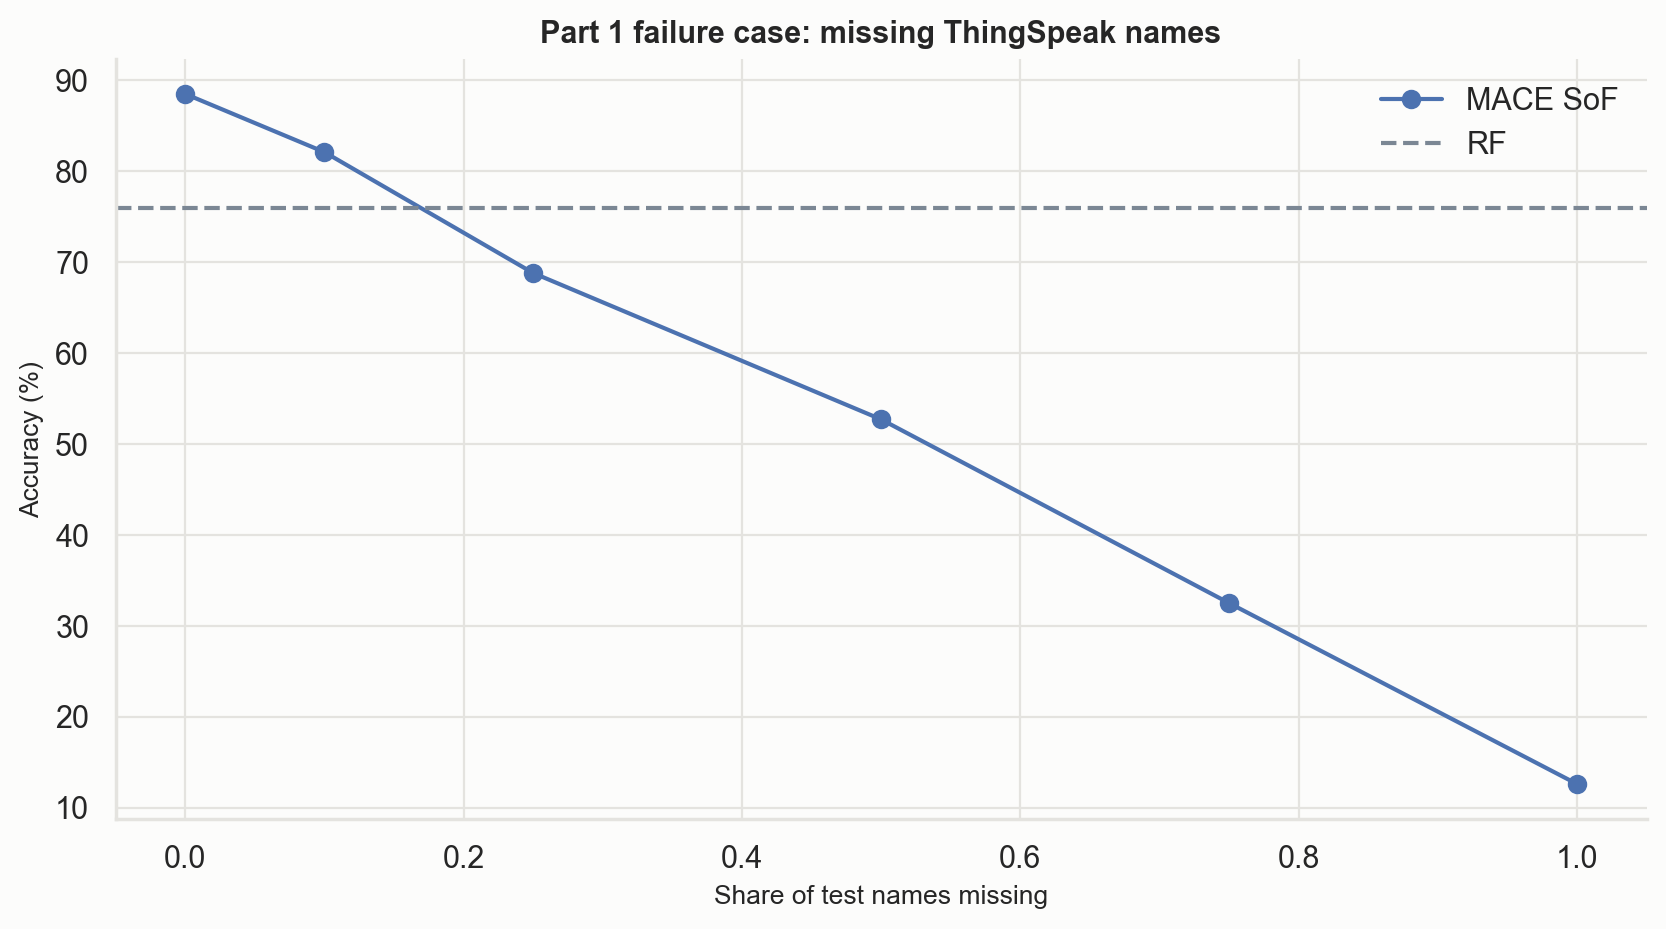

In [2]:
# collect the existing Part 1 failure evidence without recomputation
allTables['Exp22'] = runExp22Motivation(context)
display(allTables['Exp22']['failureEvidence'].round(2))
display(Image(filename=str(PART2_FIGURES_DIR / 'part1FailureEvidence.png')))

### Findings

- Part 1 already shows the failure clearly. MACE SoF reaches 88.5% on clean ThingSpeak data but falls to 68.8% with 25% of test names missing, below the 76.0% of Random Forest alone and collapses to 12.6% when every name is missing
- Formatting also matters: swapping the letter case of every name drops MACE to 73.5%, because DDL-NLP matches names case-sensitively
- Hard class elimination leaves MACE badly calibrated. Its log loss is 2.03 against 0.75 for soft voting, because a class removed by the filter receives probability zero
- DDL-NLP is weaker on names never seen in training (64.9% against 79.8% on seen names), which motivated testing unseen names as a natural failure case (H2)

## Exp23: Out-of-Fold Reliability Dataset

The gate data is reconstructed in original training-row order from the same five held-out folds as Part 1. Corrupted copies keep their source group. Coverage, partition isolation, immutability, finite features and case-fold collisions are checked

,Check,Result
0,Every training row has one clean OOF row,True
1,No source test index appears in gate groups,True
2,Original metadata unchanged,True
3,All reliability features finite,True
4,Feature order matches the pre-registered list,True


,Group,Rows,TiedRowsExcludedFromFit,ExpertDisagreement,MaceWins,RfWins
0,Overall,2226,265,18.42,89.90,10.10
1,Seen clean names,789,126,21.29,95.63,4.37
2,Unseen clean names,695,68,18.56,91.87,8.13
3,Corruption: missing,191,4,7.85,55.08,44.92
4,Corruption: case,185,24,17.30,98.14,1.86
5,Corruption: delete,187,22,14.97,91.52,8.48
6,Corruption: replace,179,21,21.23,89.24,10.76


,Rows,UniqueNamesBefore,UniqueNamesAfter,NamesMergedByCaseFold,CrossClassFoldedConflicts
0,1484,846,777,69,19


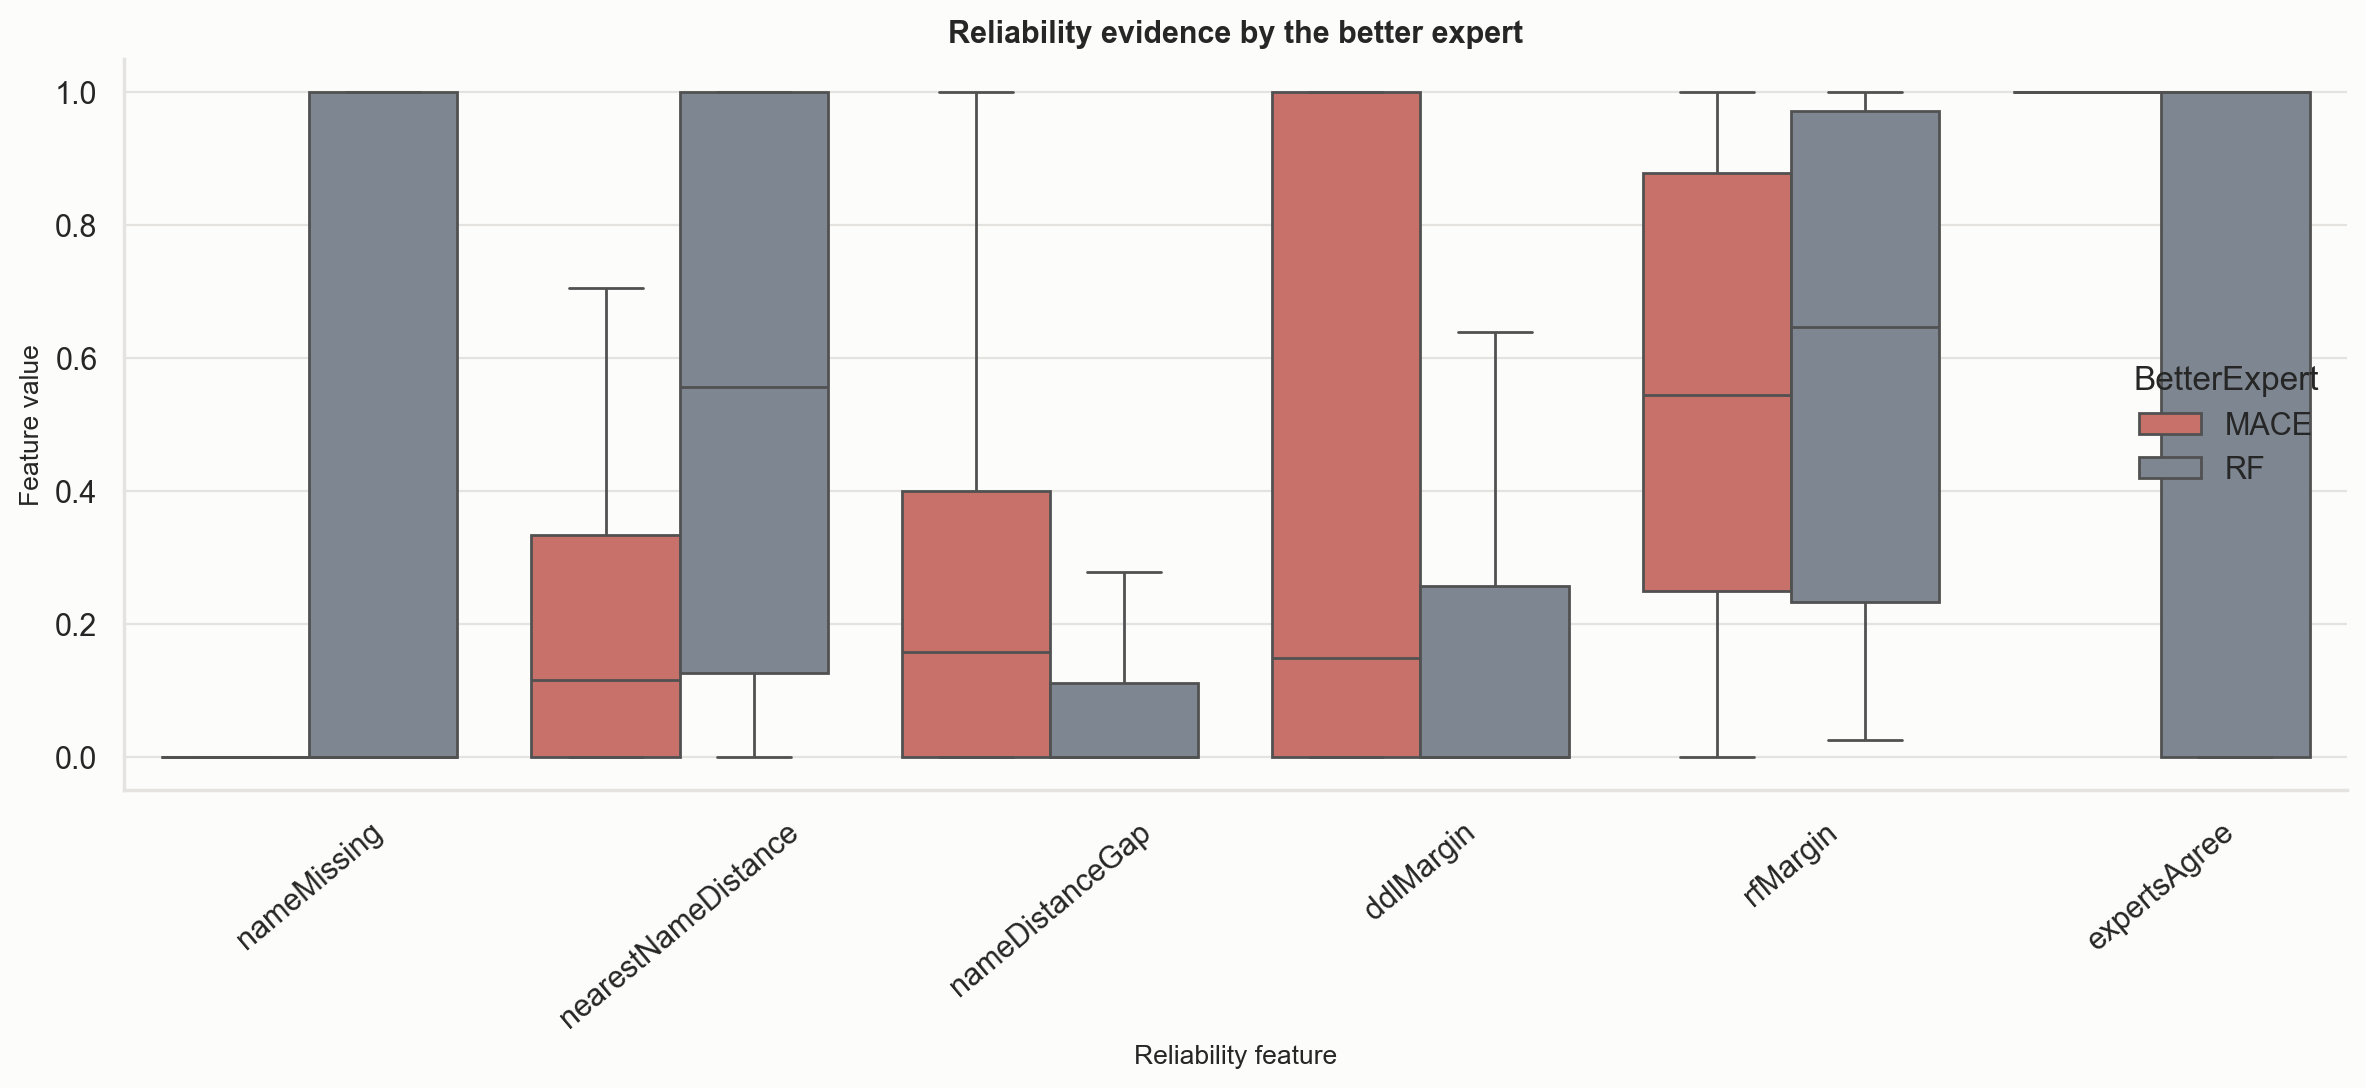

In [3]:
# build and audit the leakage-controlled gate dataset
allTables['Exp23'] = runExp23GateDataset(context)
display(allTables['Exp23']['checks'])
display(allTables['Exp23']['expertSummary'].round(2))
display(allTables['Exp23']['caseFoldAudit'])
display(Image(filename=str(PART2_FIGURES_DIR / 'gateFeatureDistributions.png')))

### Findings

- All five leakage checks pass: every training row appears once as a clean out-of-fold row, no test row enters the gate data, the original metadata is unchanged, every feature is finite and the feature order matches the pre-registered list
- The gate dataset has 2,226 rows: 1,484 clean out-of-fold rows and 742 corrupted copies (191 missing, 185 case, 187 delete, 179 replace). 265 rows where both experts give the true class equal probability are excluded from fitting
- On clean rows MACE is the better expert far more often than RF (about 92 to 96% of non-tied rows) so a sensible gate should trust MACE by default. With missing names the picture changes sharply: RF is the better expert in 44.9% of cases, compared with 8.1% on unseen clean names
- Case folding merges 846 unique training names into 777. Of the 69 merged names, 19 now map to more than one class, which is a small cost of case-insensitive matching that the gate has to absorb

## Exp24: Gate Training and Selection

Only logistic regularisation C is tuned. Grouped inner validation selects the C with the best average of clean and corrupted macro F1 among values that keep clean macro F1 within 0.5 points of MACE. If no value meets this constraint, the pre-specified fallback selects the C with the highest clean macro F1 and the result is flagged. Gate diagnostics measure routing quality, not final multiclass performance

,C,CleanF1,CorruptedF1,CleanAccuracy,CorruptedAccuracy,MaceCleanF1,MinimumAllowedCleanF1,Objective,SelectionMetric,ConstraintMet,Chosen,SelectionRule,ShortfallFromConstraint
0,0.01,74.363,67.592,84.704,79.245,75.0,74.5,70.977,F1,False,True,Pre-specified fallback: no C met the clean-F1 ...,0.137
1,0.10,74.314,67.278,84.636,79.111,75.0,74.5,70.796,F1,False,False,,0.186
2,1.00,73.872,67.866,84.704,79.111,75.0,74.5,70.869,F1,False,False,,0.628
3,10.00,73.886,66.804,85.040,79.111,75.0,74.5,70.345,F1,False,False,,0.614


,ChosenC,ConstraintMet,GateROCAUC,GateBalancedAccuracy,GatePrecision,GateRecall,GateF1,Interpretation
0,0.01,False,0.83,0.673,0.934,0.941,0.937,"Routing quality only, not final classification..."


,Feature,Coefficient,AbsoluteCoefficient
0,rfSupportForMaceChoice,0.292,0.292
1,maceSupportForRfChoice,0.236,0.236
2,expertsAgree,0.236,0.236
3,rfEntropy,0.229,0.229
4,nameDistanceGap,0.212,0.212
5,rfMaxProbability,-0.195,0.195
6,nearestNameDistance,-0.167,0.167
7,rfMargin,-0.156,0.156
8,exactNameSeen,0.122,0.122
9,nameMissing,-0.113,0.113


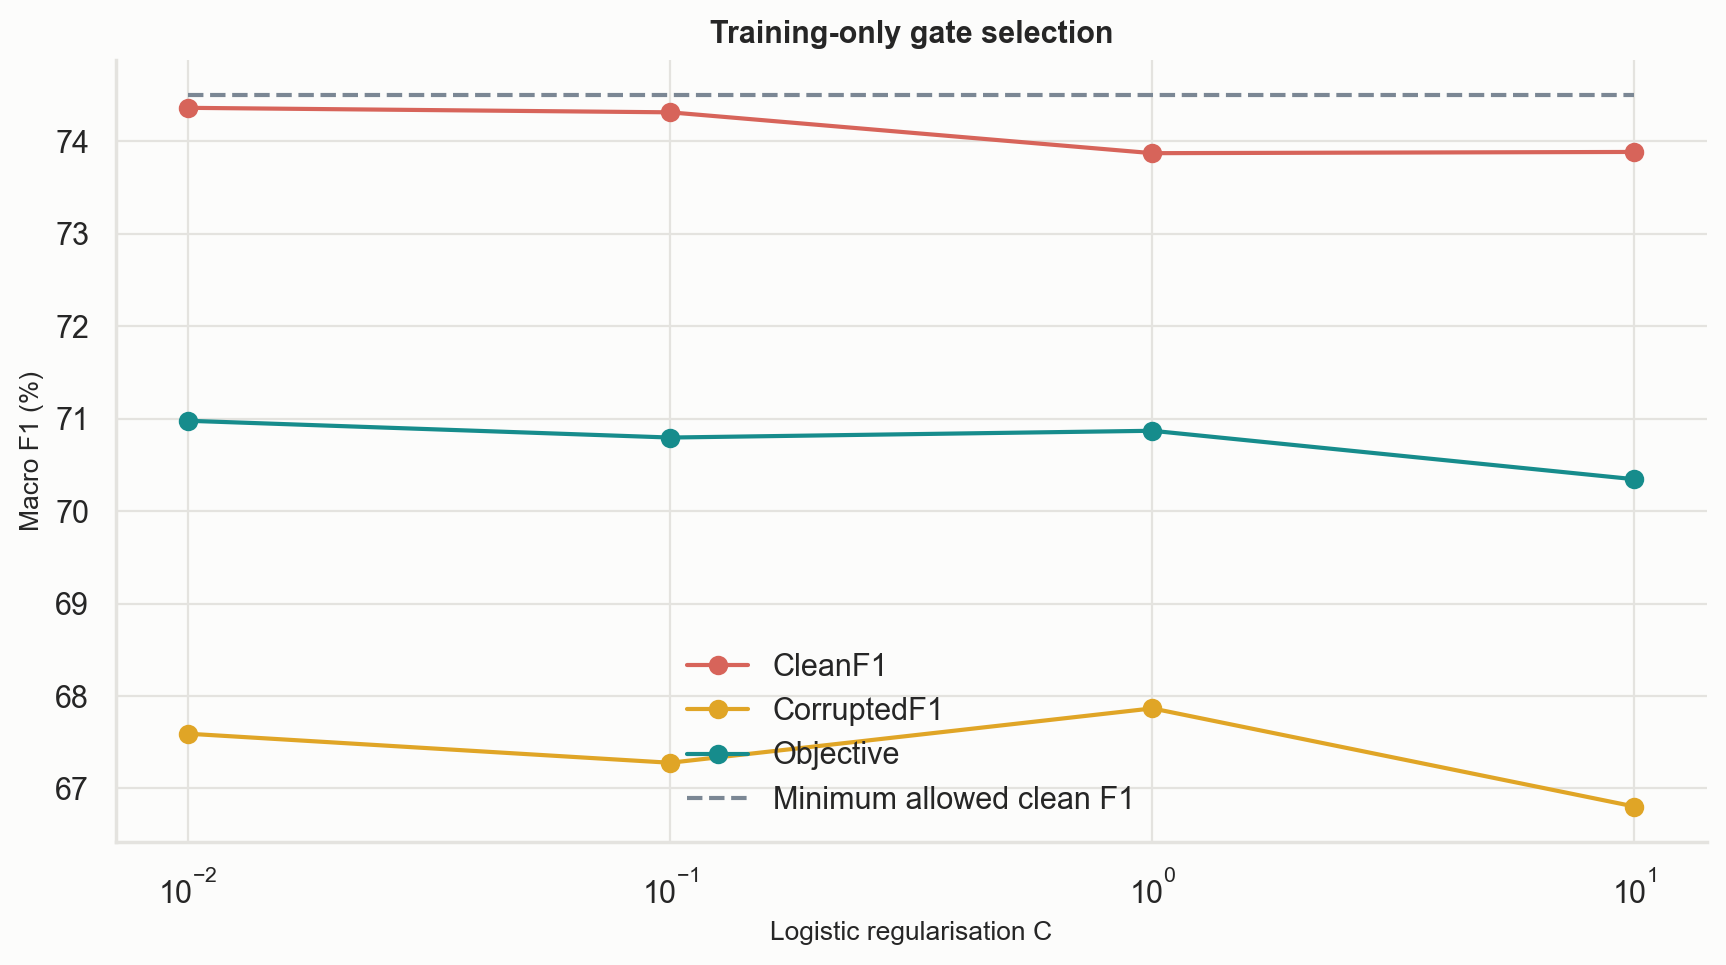

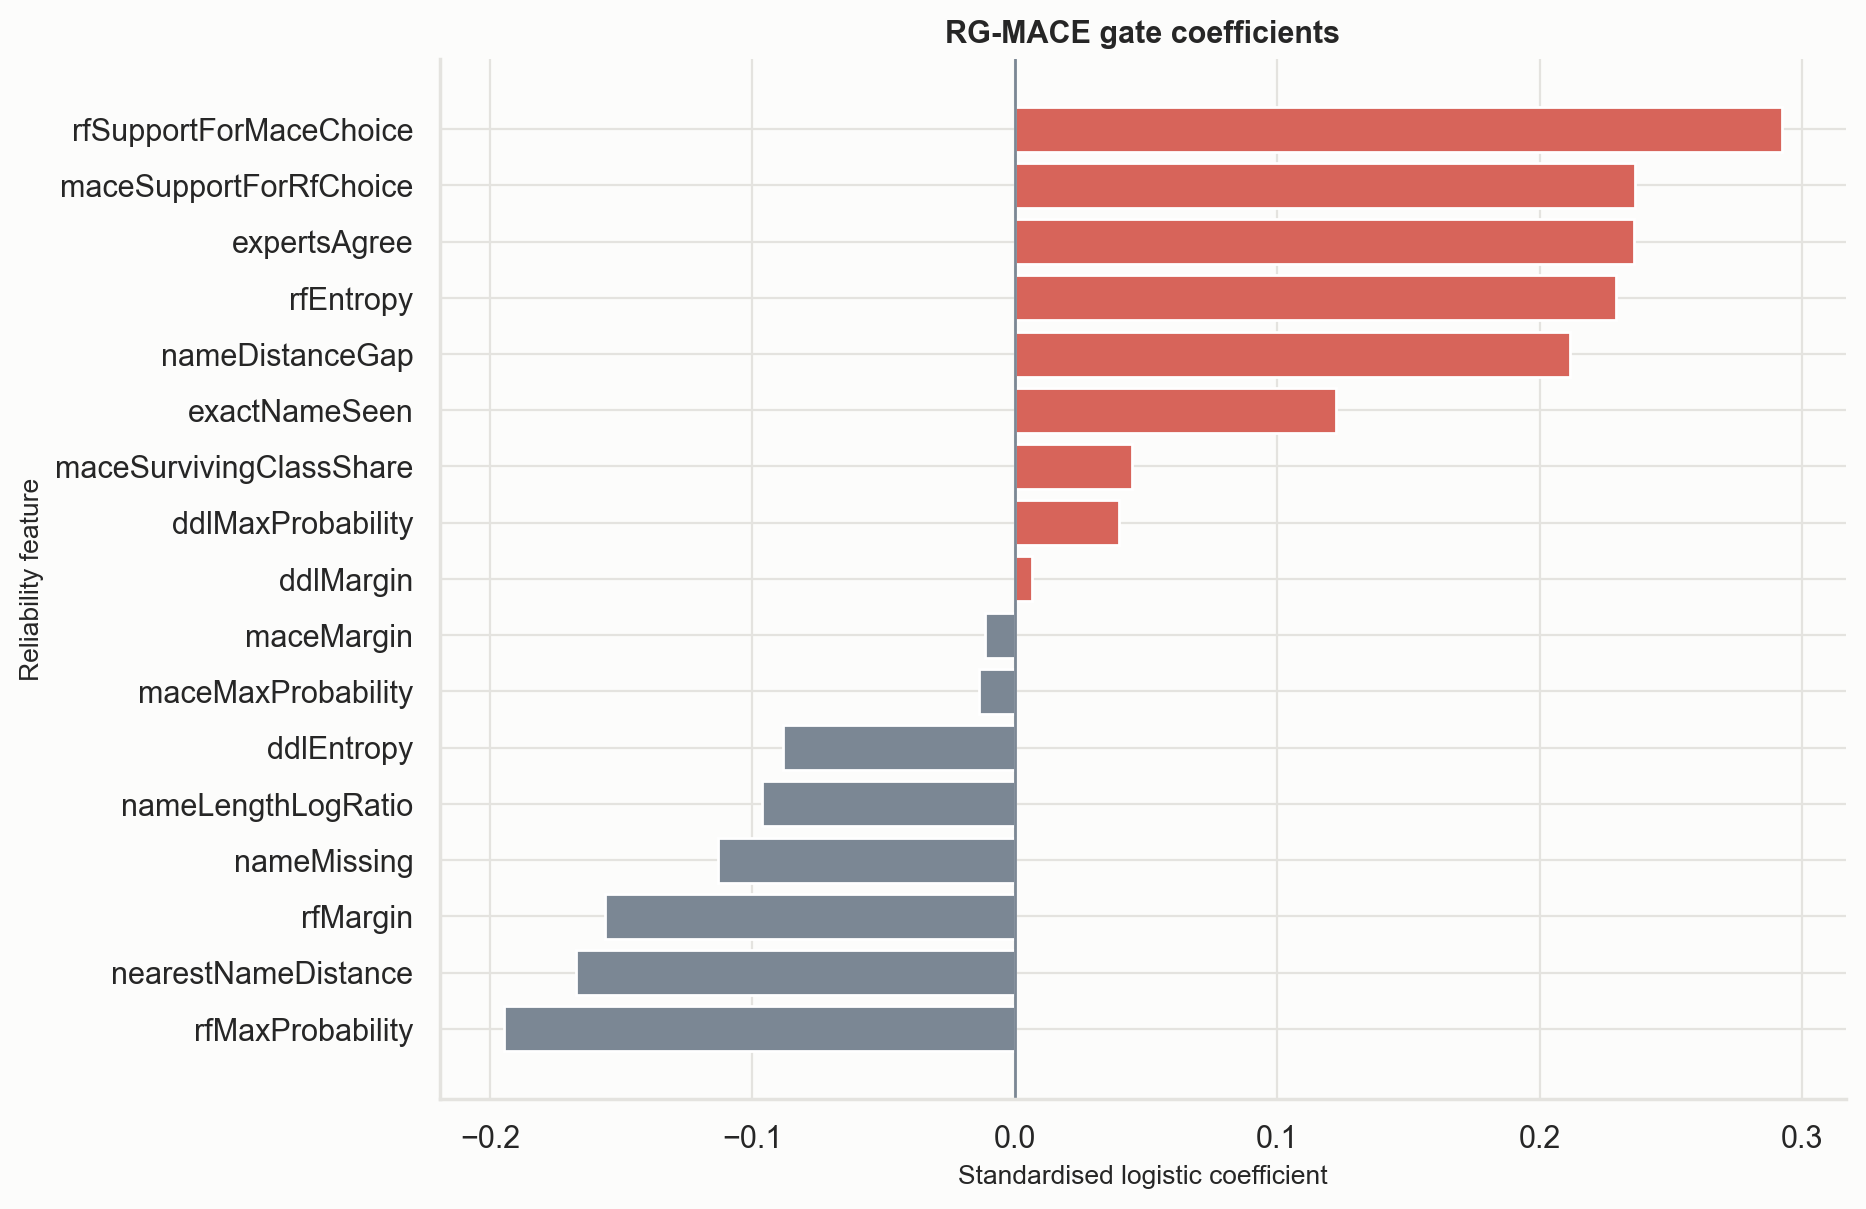

In [4]:
# select the gate and inspect its held-out routing behaviour
allTables['Exp24'] = runExp24GateSelection(context)
display(allTables['Exp24']['selection'].round(3))
display(allTables['Exp24']['diagnostics'].round(3))
display(allTables['Exp24']['coefficients'].head(12).round(3))
display(Image(filename=str(PART2_FIGURES_DIR / 'gateSelection.png')))
display(Image(filename=str(PART2_FIGURES_DIR / 'gateCoefficients.png')))

### Findings

- No value of C met the clean-F1 constraint. The best clean macro F1 was 74.36 against a required 74.50 (a 0.14-point shortfall) so the pre-specified fallback chose C = 0.01, the value with the highest clean F1. This training-only warning anticipated the small macro-F1 cost later seen on the test set
- The gate separates the better expert well (ROC-AUC 0.83), with precision 0.934 and recall 0.941 for trusting MACE. Its balanced accuracy is lower (0.673) because RF is the better expert in only about one row in ten
- The coefficients are interpretable. The gate trusts MACE more when RF itself supports MACE's choice (+0.29), when the two experts agree (+0.24), when RF is uncertain (entropy +0.23) and when the name clearly separates the classes (distance gap +0.21). It shifts weight to RF when RF is confident (-0.20), when the nearest name is far away (-0.17) and when the name is missing (-0.11)

## Exp25: Clean Test Comparison

The untouched seed-100 test set provides the direct paper, reproduction and proposed comparison. All required metrics, corrected errors, broken predictions and routing share are reported. This tests the seed-100 parts of H1

,Method,Accuracy,F1,DifferenceFromPaperAccuracy,DifferenceFromPaperF1
0,Paper MACE SoF,88.2,79.4,0.0,0.0
1,Reproduced MACE SoF,88.5,79.4,0.3,0.0
2,RG-MACE,89.2,78.8,1.0,-0.6


,Dataset,Method,Accuracy,Precision,Recall,F1,AUC,BalancedAccuracy,WeightedF1,LogLoss,Status,BrierScore
16,ThingSpeakEU,RF,76.0,51.3,54.5,51.9,90.2,54.5,74.0,1.338,Evaluated,0.344
17,ThingSpeakEU,Soft voting,80.1,59.9,59.7,58.8,97.1,59.7,78.1,0.749,Evaluated,0.322
18,ThingSpeakEU,MACE SoF,88.5,84.5,77.4,79.4,94.2,77.4,88.2,2.025,Evaluated,0.200
19,ThingSpeakEU,MACE SoF + missing-name rule,88.5,84.5,77.4,79.4,94.2,77.4,88.2,2.025,Evaluated,0.200
20,ThingSpeakEU,Case-folded MACE + missing-name rule,89.2,86.7,76.6,79.0,92.3,76.6,88.7,1.916,Evaluated,0.189
21,ThingSpeakEU,Soft stacking,87.8,75.7,74.0,74.4,97.9,74.0,87.3,0.469,Evaluated,0.192
22,ThingSpeakEU,RG-MACE (hard gate),88.4,84.7,75.8,77.8,91.7,75.8,87.5,1.421,Evaluated,0.190
23,ThingSpeakEU,RG-MACE,89.2,87.2,76.1,78.8,94.8,76.1,88.4,0.824,Evaluated,0.180


,MeanGate,RfRoutingShare,PredictionsDifferentFromMace,MaceErrorsCorrected,MaceCorrectPredictionsBroken,ChosenC,SelectedOrder,SelectedSigma
0,0.738,5.024,45,20,16,0.01,1NN-ED > DDL-NLP > RandomForest,-0.2


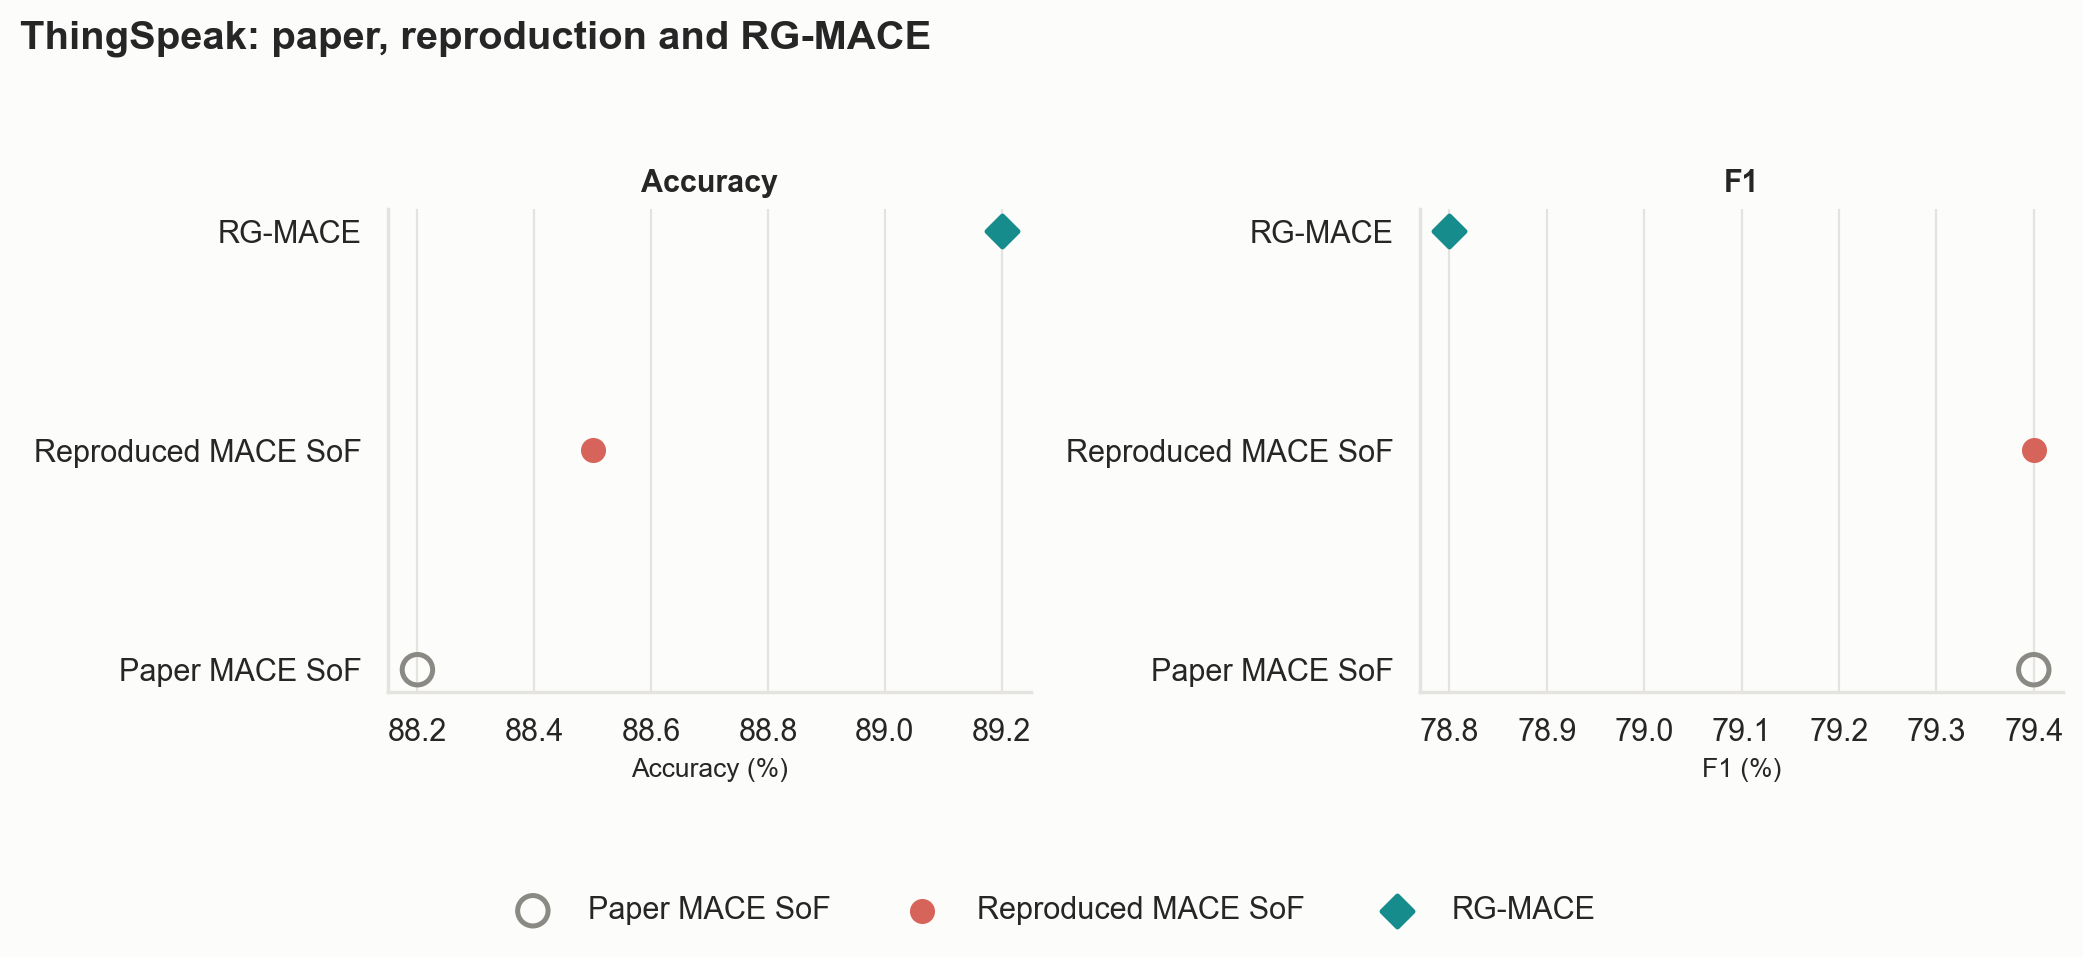

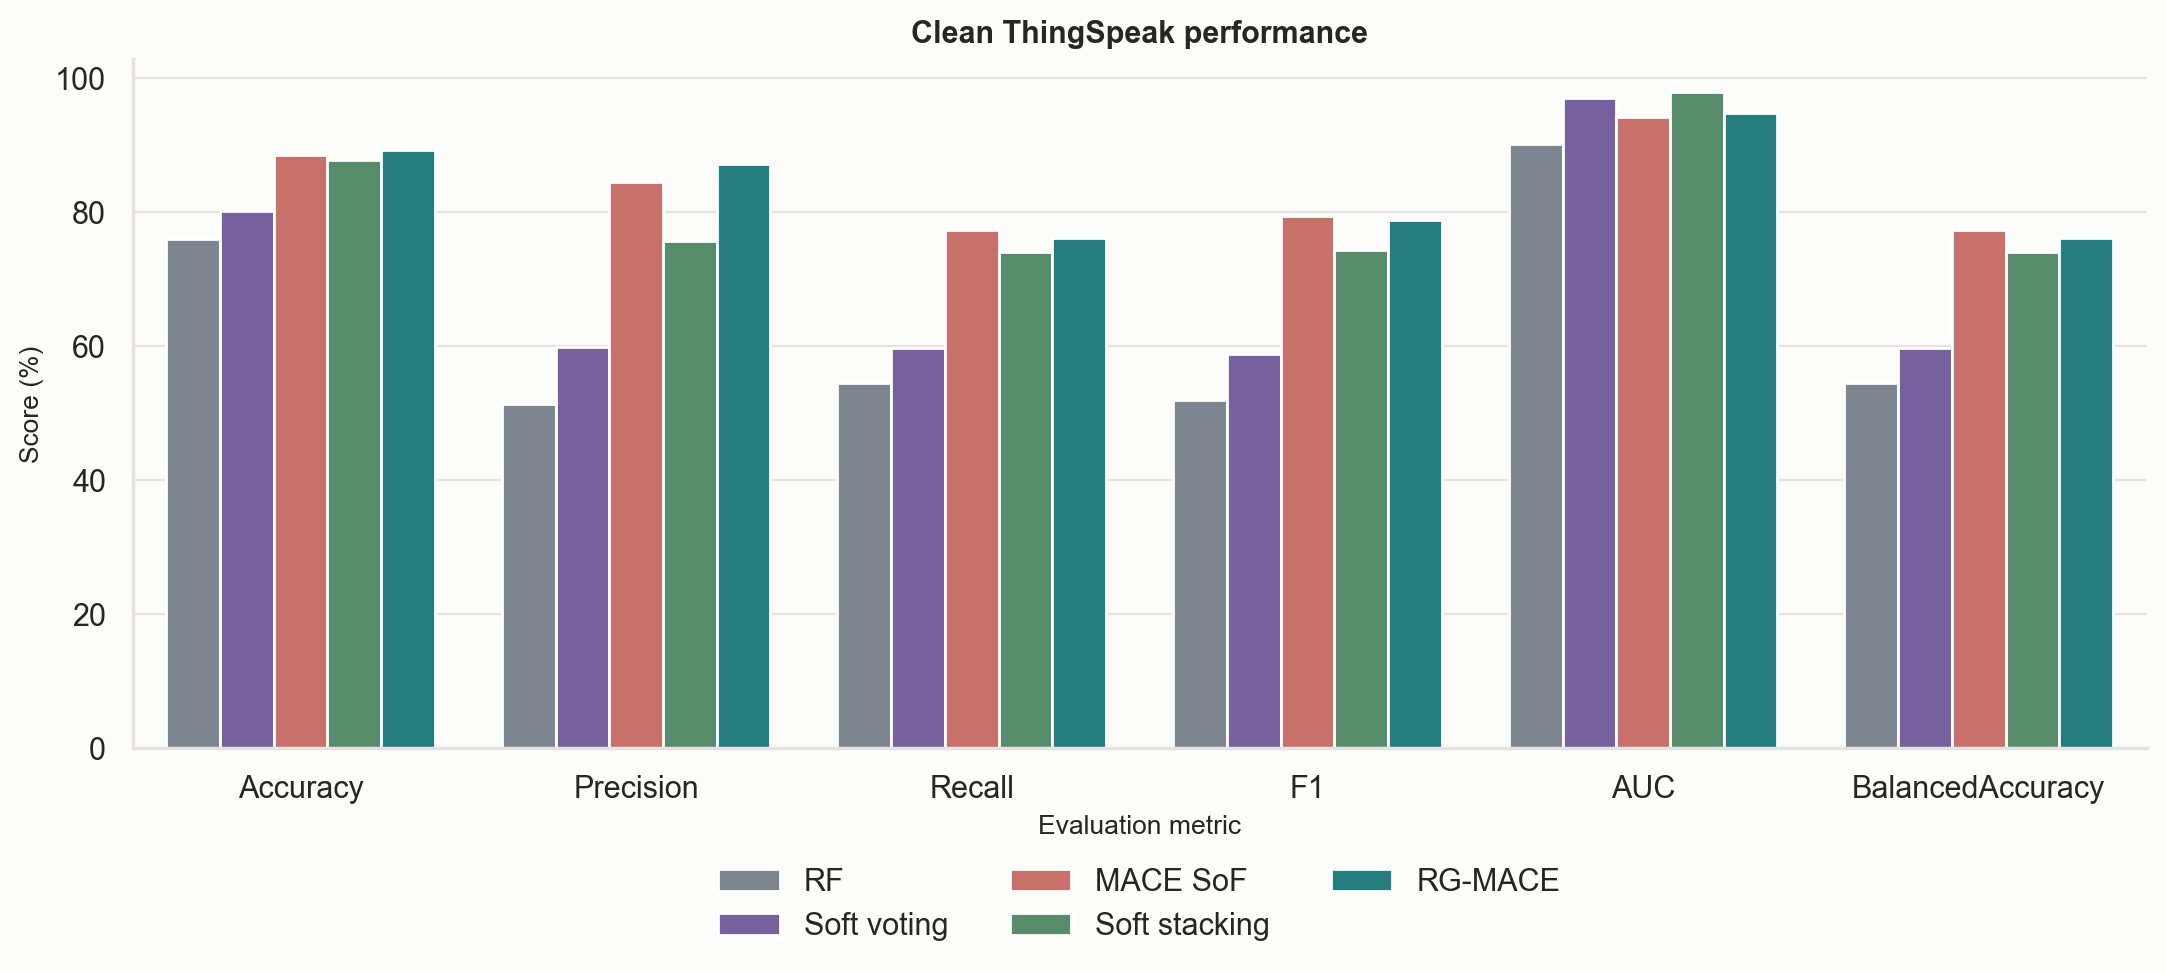

In [5]:
# evaluate clean performance and the direct paper comparison
allTables['Exp25'] = runExp25CleanComparison(context)
display(allTables['Exp25']['paperComparison'].round(2))
display(allTables['Exp25']['metrics'].query("Dataset == 'ThingSpeakEU'").round(3))
display(allTables['Exp25']['routing'].round(3))
display(Image(filename=str(PART2_FIGURES_DIR / 'cleanThreeWayComparison.png')))
display(Image(filename=str(PART2_FIGURES_DIR / 'cleanMetricComparison.png')))

### Findings

- On the paper's seed-100 split RG-MACE reaches 89.2% accuracy, 1.0 point above the paper's MACE SoF (88.2%) and 0.7 above the reproduced MACE SoF (88.5%). Its macro F1 is 78.8, 0.6 below both, just missing the 78.9% target
- The clearest clean-data gain is probability quality. Log loss falls from 2.03 to 0.82, Brier score from 0.200 to 0.180 and AUC rises from 94.2 to 94.8, because the soft mixture never assigns a class probability zero
- The gate intervenes sparingly: 5.0% of streams are routed mainly to RF and the mean gate value is 0.74. RG-MACE changes 45 predictions relative to MACE SoF, correcting 20 MACE errors and breaking 16 correct predictions
- Case folding changed the classifier order that the paper's own heuristic selects for the MACE expert, from DDL-NLP > RF to 1NN-ED > DDL-NLP > RF with sigma -0.2 so the expert itself is re-selected on training data rather than reused
- The fair baseline, case-folded MACE with the missing-name rule, matches RG-MACE on accuracy (89.2%) and has slightly higher macro F1 (79.0), but its log loss is 1.92 against 0.82. Generic soft stacking has the best log loss (0.47) and AUC (97.9) but lower accuracy (87.8%) and much lower macro F1 (74.4). UrbObs and Swissex are not applicable because they have no metadata and MACE already equals RF there

## Exp26: Natural Reliability and Leakage-Aware Splits

Seen and unseen names are evaluated separately across seven splits, with inference at the seed level. The full pipeline is refitted under stratified, duplicate-aware and channel-grouped splits for clean and 25% missing names. This is the primary evidence for H2 and H5

,Subset,Method,Rows,AccuracyMean,AccuracyStd,F1Mean,F1Std
0,Seen,Case-folded MACE + missing-name rule,2477,93.39,3.91,87.74,12.46
1,Seen,MACE SoF,2477,92.94,3.80,87.61,12.18
2,Seen,MACE SoF + missing-name rule,2477,92.94,3.80,87.61,12.18
3,Seen,RF,2477,76.09,1.39,55.13,5.49
4,Seen,RG-MACE,2477,92.94,4.06,86.99,12.87
5,Unseen,Case-folded MACE + missing-name rule,1982,79.30,2.89,60.83,6.64
6,Unseen,MACE SoF,1982,79.09,2.41,59.97,4.70
7,Unseen,MACE SoF + missing-name rule,1982,79.09,2.41,59.97,4.70
8,Unseen,RF,1982,71.07,2.27,42.81,3.06
9,Unseen,RG-MACE,1982,79.33,3.22,58.97,6.08


Accuracy              F1  \
Condition                                             Clean Missing25 Clean   
SplitStrategy Method                                                          
channelAware  Case-folded MACE + missing-name rule     87.0      82.4  80.6   
              MACE SoF                                 86.7      68.4  80.6   
              MACE SoF + missing-name rule             86.7      82.0  80.6   
              RF                                       72.5      72.5  49.6   
              RG-MACE                                  87.1      82.3  80.8   
groupAware    Case-folded MACE + missing-name rule     88.1      85.6  84.0   
              MACE SoF                                 90.4      70.9  84.2   
              MACE SoF + missing-name rule             90.4      87.1  84.2   
              RF                                       73.7      73.7  45.4   
              RG-MACE                                  89.8      86.3  84.6   
stratified    Case-folded MACE + missing-name rule     89.2      87.1  79.0   
              MACE SoF                                 88.5      68.8  79.4   
              MACE SoF + missing-name rule             88.5      86.5  79.4   
              RF                                       76.0      76.0  51.9   
              RG-MACE                                  89.2      86.7  78.8   

                                                               AUC            \
Condition                                          Missing25 Clean Missing25   
SplitStrategy Method                                                           
channelAware  Case-folded MACE + missing-name rule      72.2  93.7      94.8   
              MACE SoF                                  68.7  92.6      81.8   
              MACE SoF + missing-name rule              71.8  92.6      94.2   
              RF                                        49.6  92.7      92.7   
              RG-MACE                                   73.0  98.0      96.1   
groupAware    Case-folded MACE + missing-name rule      78.6  92.8      92.0   
              MACE SoF                                  73.1  93.5      82.6   
              MACE SoF + missing-name rule              79.3  93.5      92.4   
              RF                                        45.4  90.1      90.1   
              RG-MACE                                   78.7  96.1      94.5   
stratified    Case-folded MACE + missing-name rule      74.0  92.3      92.0   
              MACE SoF                                  67.0  94.2      82.1   
              MACE SoF + missing-name rule              73.2  94.2      92.0   
              RF                                        51.9  90.2      90.2   
              RG-MACE                                   73.8  94.8      94.2   

                                                   LogLoss            \
Condition                                            Clean Missing25   
SplitStrategy Method                                                   
channelAware  Case-folded MACE + missing-name rule   1.876     1.641   
              MACE SoF                               2.202     9.313   
              MACE SoF + missing-name rule           2.202     1.931   
              RF                                     1.186     1.186   
              RG-MACE                                0.468     0.732   
groupAware    Case-folded MACE + missing-name rule   2.840     2.399   
              MACE SoF                               1.741     9.293   
              MACE SoF + missing-name rule           1.741     1.623   
              RF                                     1.286     1.286   
              RG-MACE                                0.418     0.647   
stratified    Case-folded MACE + missing-name rule   1.916     1.775   
              MACE SoF                               2.025     9.733   
              MACE SoF + missing-name rule           2.025     1.993   
              RF                   

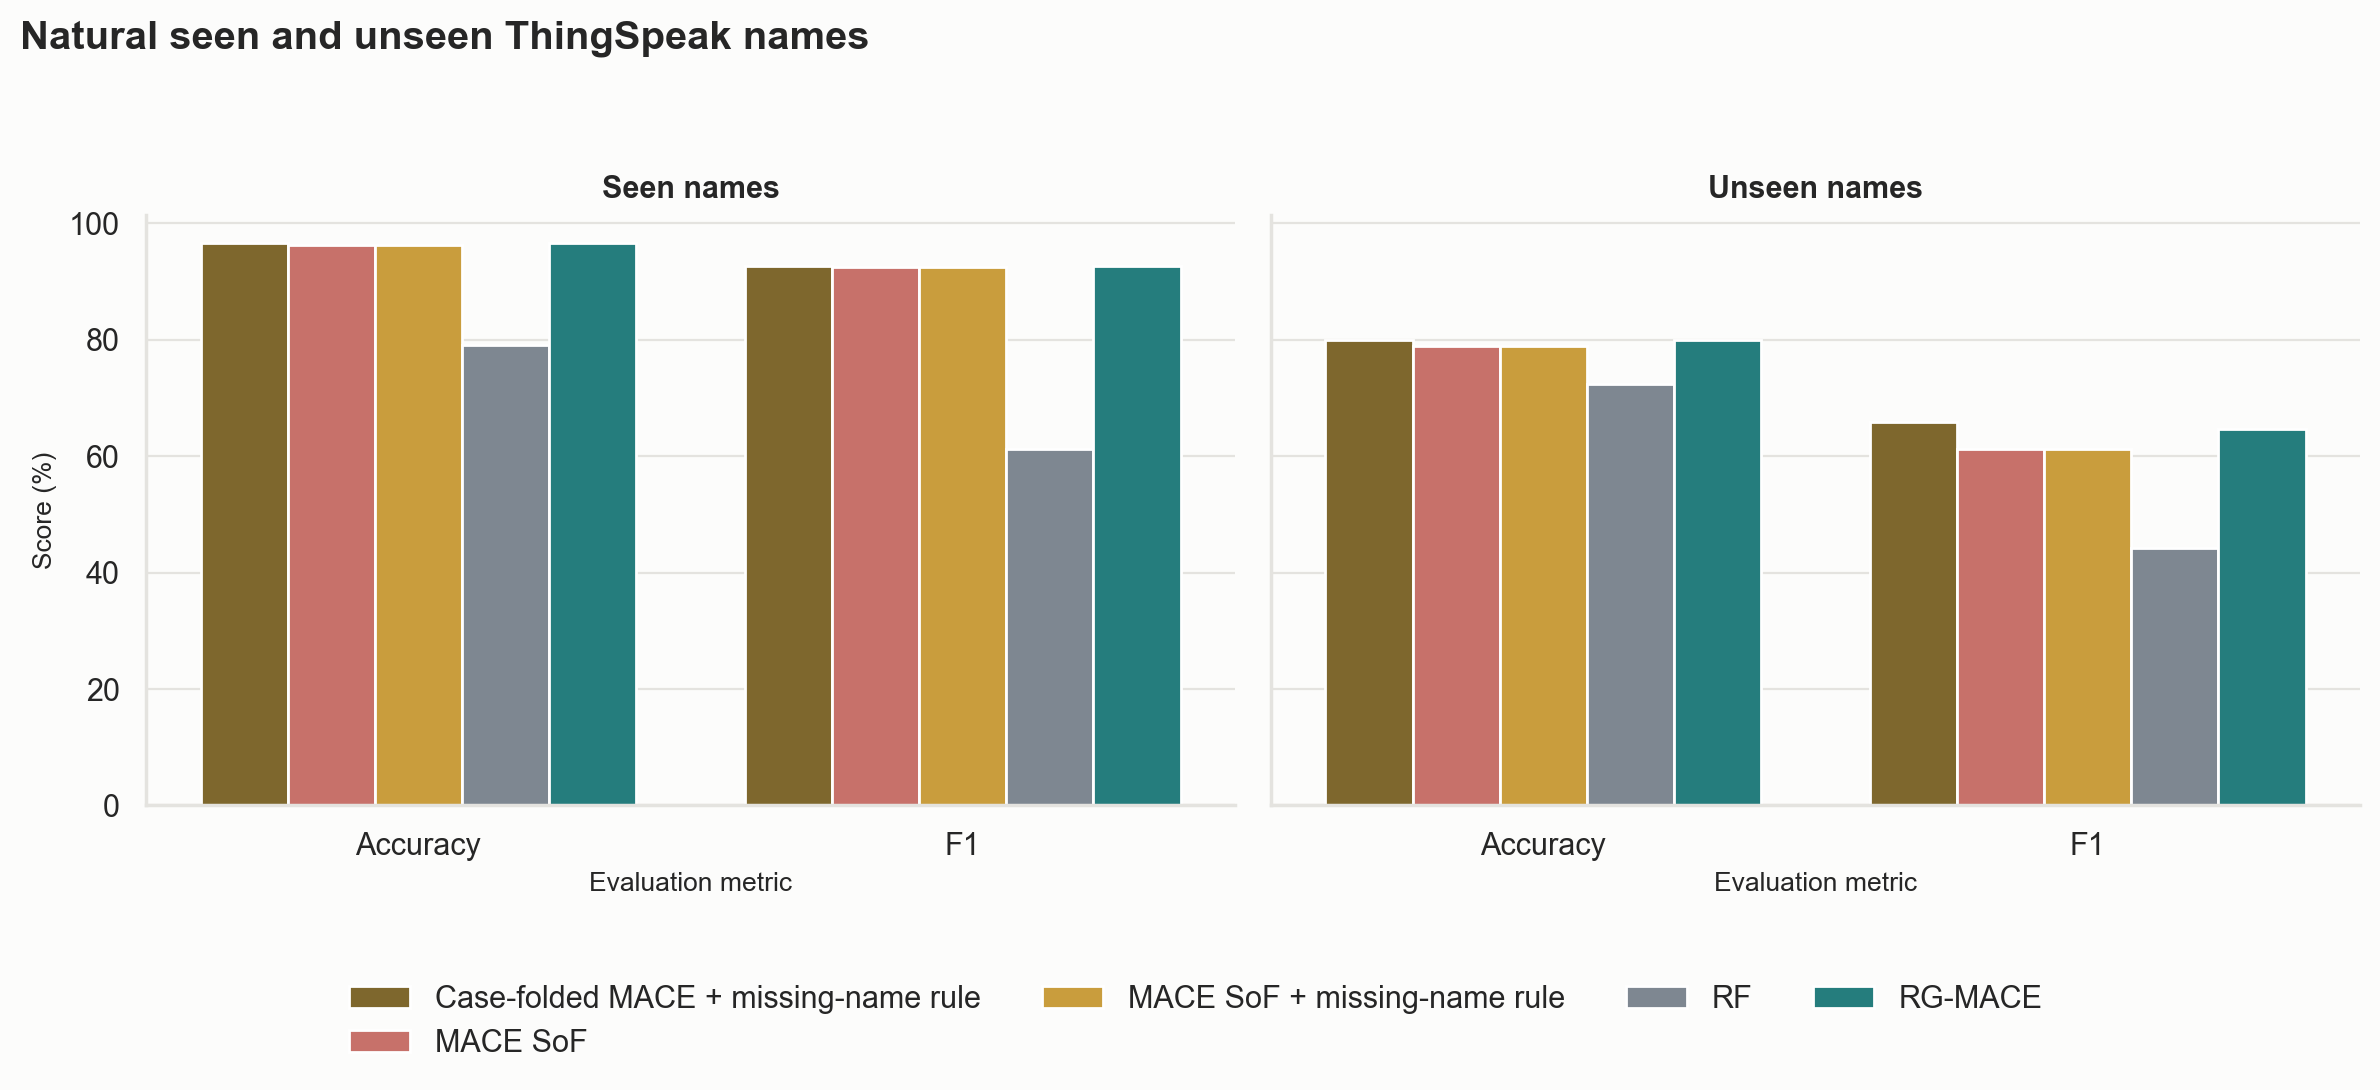

In [6]:
# test natural unseen names and leakage-aware split protocols
allTables['Exp26'] = runExp26NaturalFailure(context)
display(allTables['Exp26']['subsetSummary'].round(2))
display(allTables['Exp26']['splitResults'].pivot_table(
    index=['SplitStrategy', 'Method'], columns='Condition',
    values=['Accuracy', 'F1', 'AUC', 'LogLoss', 'BrierScore'], aggfunc='first', sort=False
).round(3))
display(Image(filename=str(PART2_FIGURES_DIR / 'naturalNameSubsets.png')))

### Findings

- H2 is not supported. On names never seen in training, RG-MACE averages 79.3% accuracy over seven splits against 79.1% for MACE SoF and the lower 95% bound of the paired difference is below zero for both accuracy (-0.77) and macro F1 (-5.28)
- The reason is informative: unseen names are not actually unreliable. MACE still reaches 79.1% on them against 71.1% for RF, because fuzzy name matching finds useful similar names so there is little for a gate to correct. The real reliability failures are missing and badly formatted names
- The improvement holds when leakage is controlled. On the channel-grouped split, where no test channel appears in training, RG-MACE is 0.4 points above MACE SoF on clean data (87.1% against 86.7%) and 13.9 points above it with 25% of names missing (82.3% against 68.4%). Its log loss is 0.47 against 2.20 on clean data
- On the duplicate-aware split RG-MACE is 0.6 points below MACE on clean data (89.8% against 90.4%) but 15.4 points above it with 25% of names missing (86.3% against 70.9%), again with much lower log loss (0.42 against 1.74)
- Across all three splits RG-MACE and the case-folded rule reach similar accuracy with missing names while RG-MACE has clearly better log loss and AUC

## Exp27: Metadata Robustness

Missing, case, deletion and replacement corruption are applied to test names only. Three fixed seeds are averaged. The 0-50% interval is primary while 75-100% is an extreme stress test. This tests H3 and H4

,Mode,Method,Range,AccuracyAUC,F1AUC
0,case,Case-folded MACE + missing-name rule,Primary_0_50,89.20,79.00
1,case,Case-folded MACE + missing-name rule,Secondary_0_100,89.20,79.00
2,case,MACE SoF,Primary_0_50,85.04,74.41
3,case,MACE SoF,Secondary_0_100,81.10,67.66
4,case,MACE SoF + missing-name rule,Primary_0_50,85.04,74.41
...,...,...,...,...,...
59,replace,RG-MACE (hard gate),Secondary_0_100,85.78,72.43
60,replace,Soft stacking,Primary_0_50,87.26,72.34
61,replace,Soft stacking,Secondary_0_100,86.71,70.65
62,replace,Soft voting,Primary_0_50,79.37,57.86


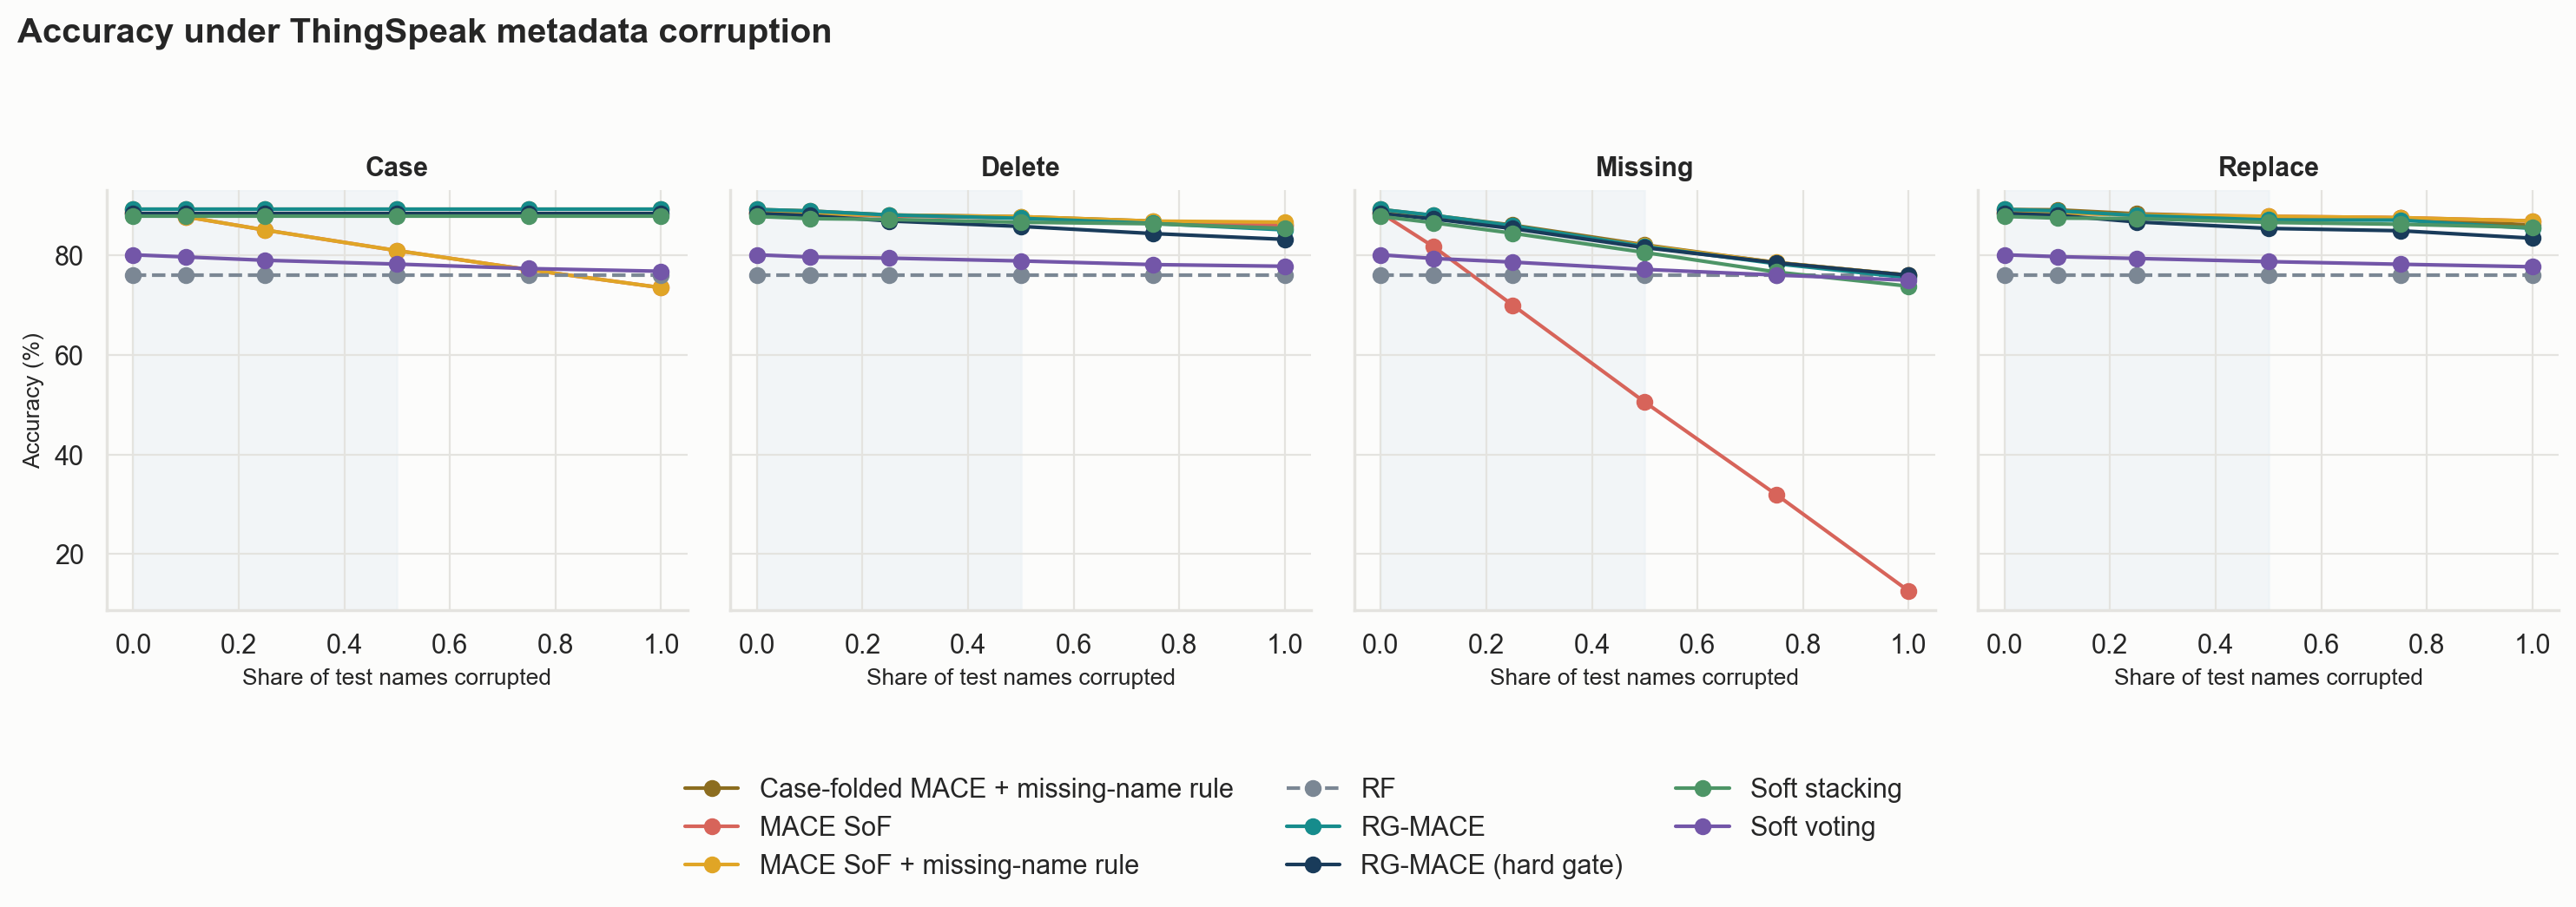

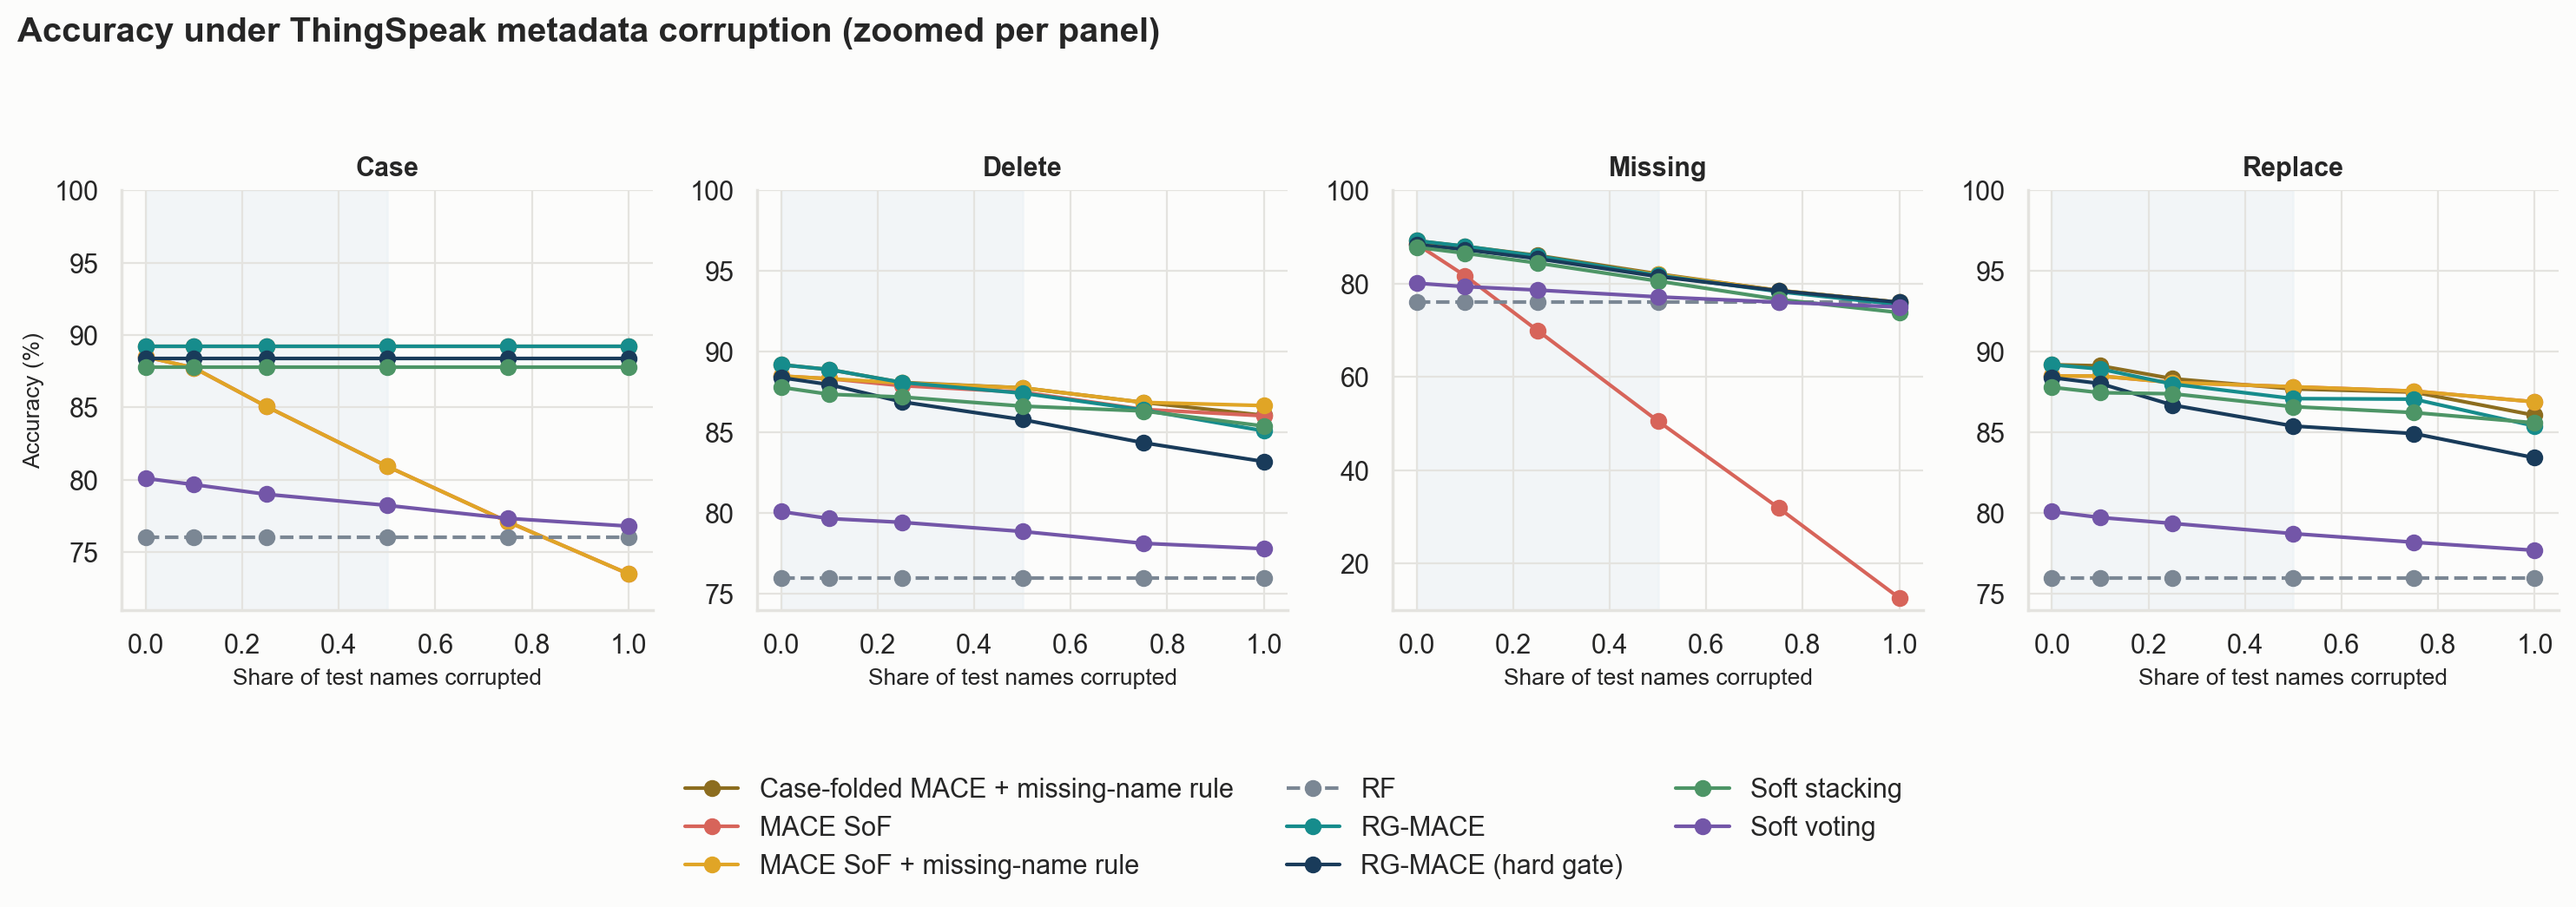

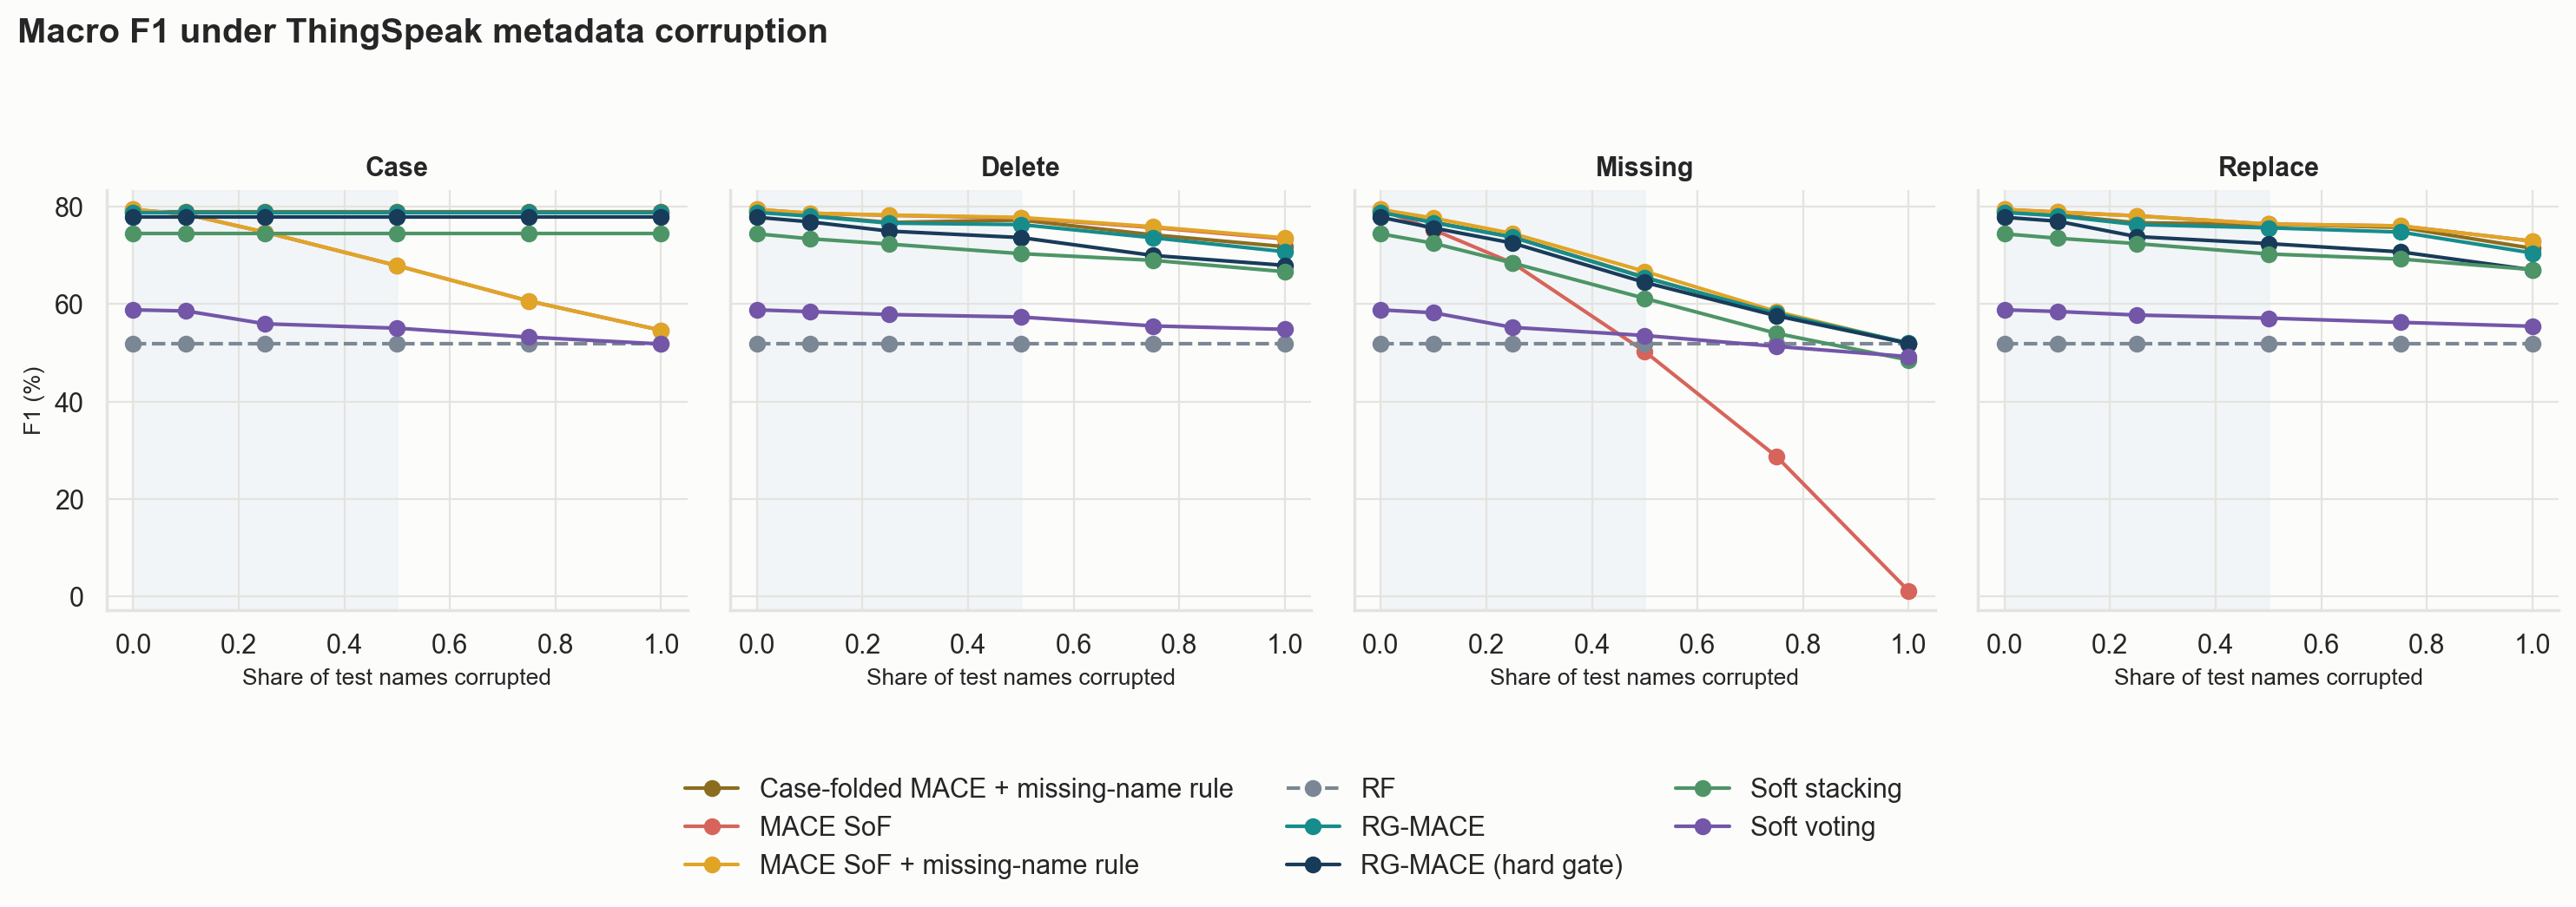

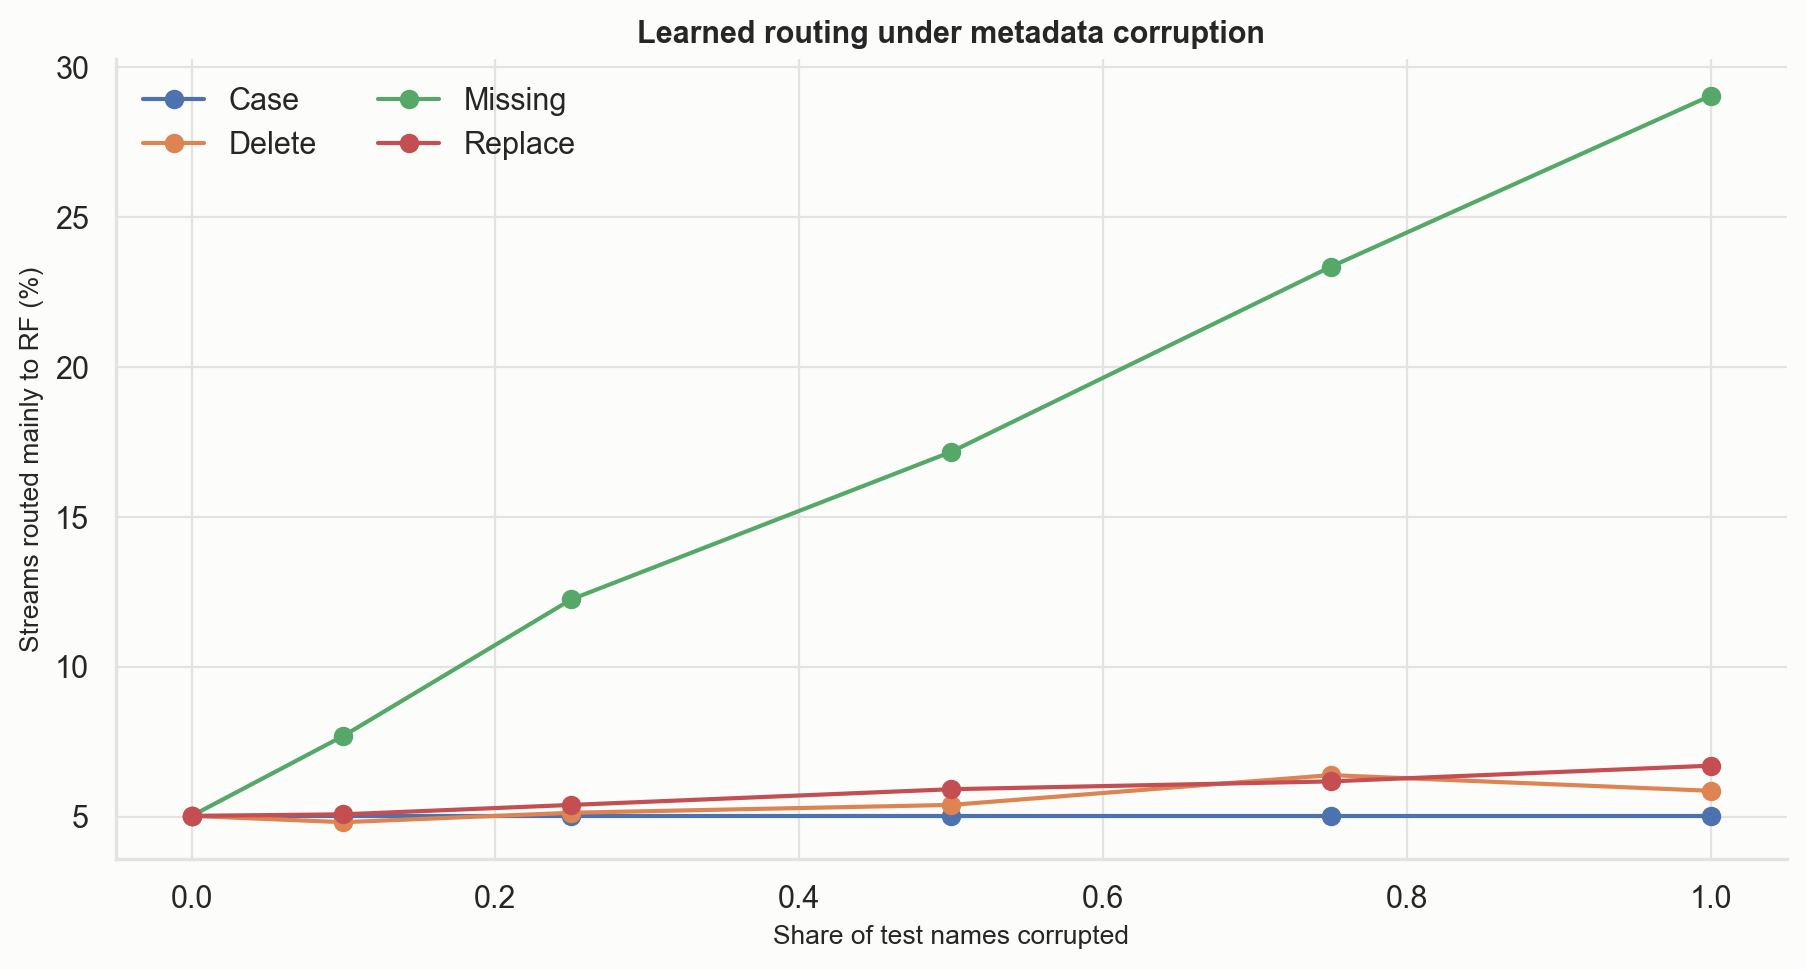

In [7]:
# compare all methods across fixed corruption modes and rates
allTables['Exp27'] = runExp27Robustness(context)
display(allTables['Exp27']['areas'].round(2))
display(Image(filename=str(PART2_FIGURES_DIR / 'metadataRobustnessAccuracy.png')))
display(Image(filename=str(PART2_FIGURES_DIR / 'metadataRobustnessAccuracyZoom.png')))
display(Image(filename=str(PART2_FIGURES_DIR / 'metadataRobustnessF1.png')))
display(Image(filename=str(PART2_FIGURES_DIR / 'metadataRoutingShare.png')))

### Findings

- Missing names are where RG-MACE helps most. Over the primary 0-50% range its average accuracy is 85.7% against 69.9% for MACE SoF (+15.8 points) and with every name missing it keeps 75.5% instead of collapsing to 12.6%
- Case corruption is handled by case folding: RG-MACE and the case-folded rule both stay flat at 89.2% however many names are case-swapped while MACE SoF falls to 73.5%
- One-character deletions and replacements barely affect any MACE-based method, because fuzzy matching tolerates small typos. RG-MACE is +0.27 points above MACE on deletion and -0.05 on replacement, effectively a tie so the pre-registered "all four modes" criterion is missed on replacement
- Against the case-folded rule, RG-MACE is essentially level on accuracy in every mode (for example 85.7% against 85.9% for missing names) so its advantage over the rule is in probability quality rather than accuracy. Against generic soft stacking it is higher in every mode at seed 100 (for example 85.7% against 84.3% for missing names)
- The routing plot shows the learned behaviour: as more names go missing, the share of streams routed mainly to RF rises, without any hard-coded rule

## Exp28: Repeated-Split Robustness

The complete RG-MACE pipeline is rebuilt for seven fixed seeds. Paired t intervals and Wilcoxon tests compare seed-level differences on clean data and at 25% missing names. This provides the main H1 non-inferiority evidence

,Condition,Method,Accuracy_mean,Accuracy_std,Accuracy_min,Accuracy_max,Precision_mean,Precision_std,Precision_min,Precision_max,...,WeightedF1_max,LogLoss_mean,LogLoss_std,LogLoss_min,LogLoss_max,BrierScore_mean,BrierScore_std,BrierScore_min,BrierScore_max,GateConstraintMetSeeds
0,Clean,Case-folded MACE + missing-name rule,87.11,3.22,80.1,89.5,80.63,9.12,60.4,86.7,...,89.3,2.70,1.80,1.33,6.65,0.22,0.07,0.18,0.38,1 of 7
1,Clean,MACE SoF,86.77,2.86,80.4,88.5,81.04,9.78,60.1,89.6,...,88.2,2.66,1.66,1.57,6.38,0.23,0.06,0.20,0.37,1 of 7
2,Clean,MACE SoF + missing-name rule,86.77,2.86,80.4,88.5,81.04,9.78,60.1,89.6,...,88.2,2.66,1.66,1.57,6.38,0.23,0.06,0.20,0.37,1 of 7
3,Clean,RF,73.87,1.52,71.7,76.0,52.69,4.69,46.0,61.0,...,74.0,1.41,0.12,1.27,1.62,0.37,0.01,0.34,0.38,1 of 7
4,Clean,RG-MACE,86.86,3.38,79.7,89.3,78.90,9.74,60.3,87.2,...,88.8,0.82,0.27,0.55,1.28,0.21,0.05,0.17,0.32,1 of 7
5,Clean,Soft stacking,87.77,0.97,86.3,88.9,79.77,3.72,74.9,83.7,...,88.6,0.45,0.06,0.41,0.59,0.19,0.01,0.17,0.21,1 of 7
6,Clean,Soft voting,78.26,1.38,76.5,80.1,62.39,5.52,55.3,70.3,...,78.9,0.76,0.01,0.75,0.78,0.33,0.01,0.32,0.34,1 of 7
7,Missing25,Case-folded MACE + missing-name rule,84.06,2.89,78.2,87.1,74.73,7.33,61.4,82.8,...,86.4,2.46,1.40,1.45,5.53,0.26,0.06,0.21,0.39,1 of 7
8,Missing25,MACE SoF,74.34,7.36,67.2,84.6,74.90,9.56,55.9,82.9,...,84.0,7.00,3.25,2.37,9.73,0.47,0.16,0.26,0.61,1 of 7
9,Missing25,MACE SoF + missing-name rule,83.79,2.53,78.8,86.5,74.97,8.21,61.4,86.1,...,85.8,2.45,1.28,1.64,5.31,0.26,0.05,0.22,0.38,1 of 7


,Condition,Comparison,Metric,MeanDifference,Lower95,Upper95,WilcoxonStatistic,WilcoxonPValue,MedianDifference
0,Clean,RG-MACE - MACE SoF,Accuracy,0.086,-0.702,0.873,11.5,0.734,-0.300
1,Clean,RG-MACE - MACE SoF,F1,-2.014,-5.106,1.077,5.0,0.156,-1.300
2,Clean,RG-MACE - MACE SoF,AUC,3.486,-0.777,7.749,3.0,0.078,2.600
3,Clean,RG-MACE - MACE SoF,LogLoss,-1.837,-3.198,-0.477,0.0,0.016,-1.202
4,Clean,RG-MACE - MACE SoF,BrierScore,-0.020,-0.040,-0.000,3.0,0.078,-0.020
5,Clean,RG-MACE - MACE SoF + missing-name rule,Accuracy,0.086,-0.702,0.873,11.5,0.734,-0.300
6,Clean,RG-MACE - MACE SoF + missing-name rule,F1,-2.014,-5.106,1.077,5.0,0.156,-1.300
7,Clean,RG-MACE - MACE SoF + missing-name rule,AUC,3.486,-0.777,7.749,3.0,0.078,2.600
8,Clean,RG-MACE - MACE SoF + missing-name rule,LogLoss,-1.837,-3.198,-0.477,0.0,0.016,-1.202
9,Clean,RG-MACE - MACE SoF + missing-name rule,BrierScore,-0.020,-0.040,-0.000,3.0,0.078,-0.020


,Seed,ChosenC,ConstraintMet,CleanF1,MinimumAllowedCleanF1,ShortfallFromConstraint,SelectionRule
0,7,0.01,False,79.842,80.055,0.212,Pre-specified fallback: no C met the clean-F1 ...
1,21,0.01,False,79.447,79.668,0.221,Pre-specified fallback: no C met the clean-F1 ...
2,42,0.01,False,75.408,76.866,1.458,Pre-specified fallback: no C met the clean-F1 ...
3,77,10.00,False,74.577,75.368,0.790,Pre-specified fallback: no C met the clean-F1 ...
4,100,0.01,False,74.363,74.500,0.137,Pre-specified fallback: no C met the clean-F1 ...
5,123,0.01,False,81.010,81.032,0.022,Pre-specified fallback: no C met the clean-F1 ...
6,202,0.01,True,60.697,60.333,-0.364,Constrained


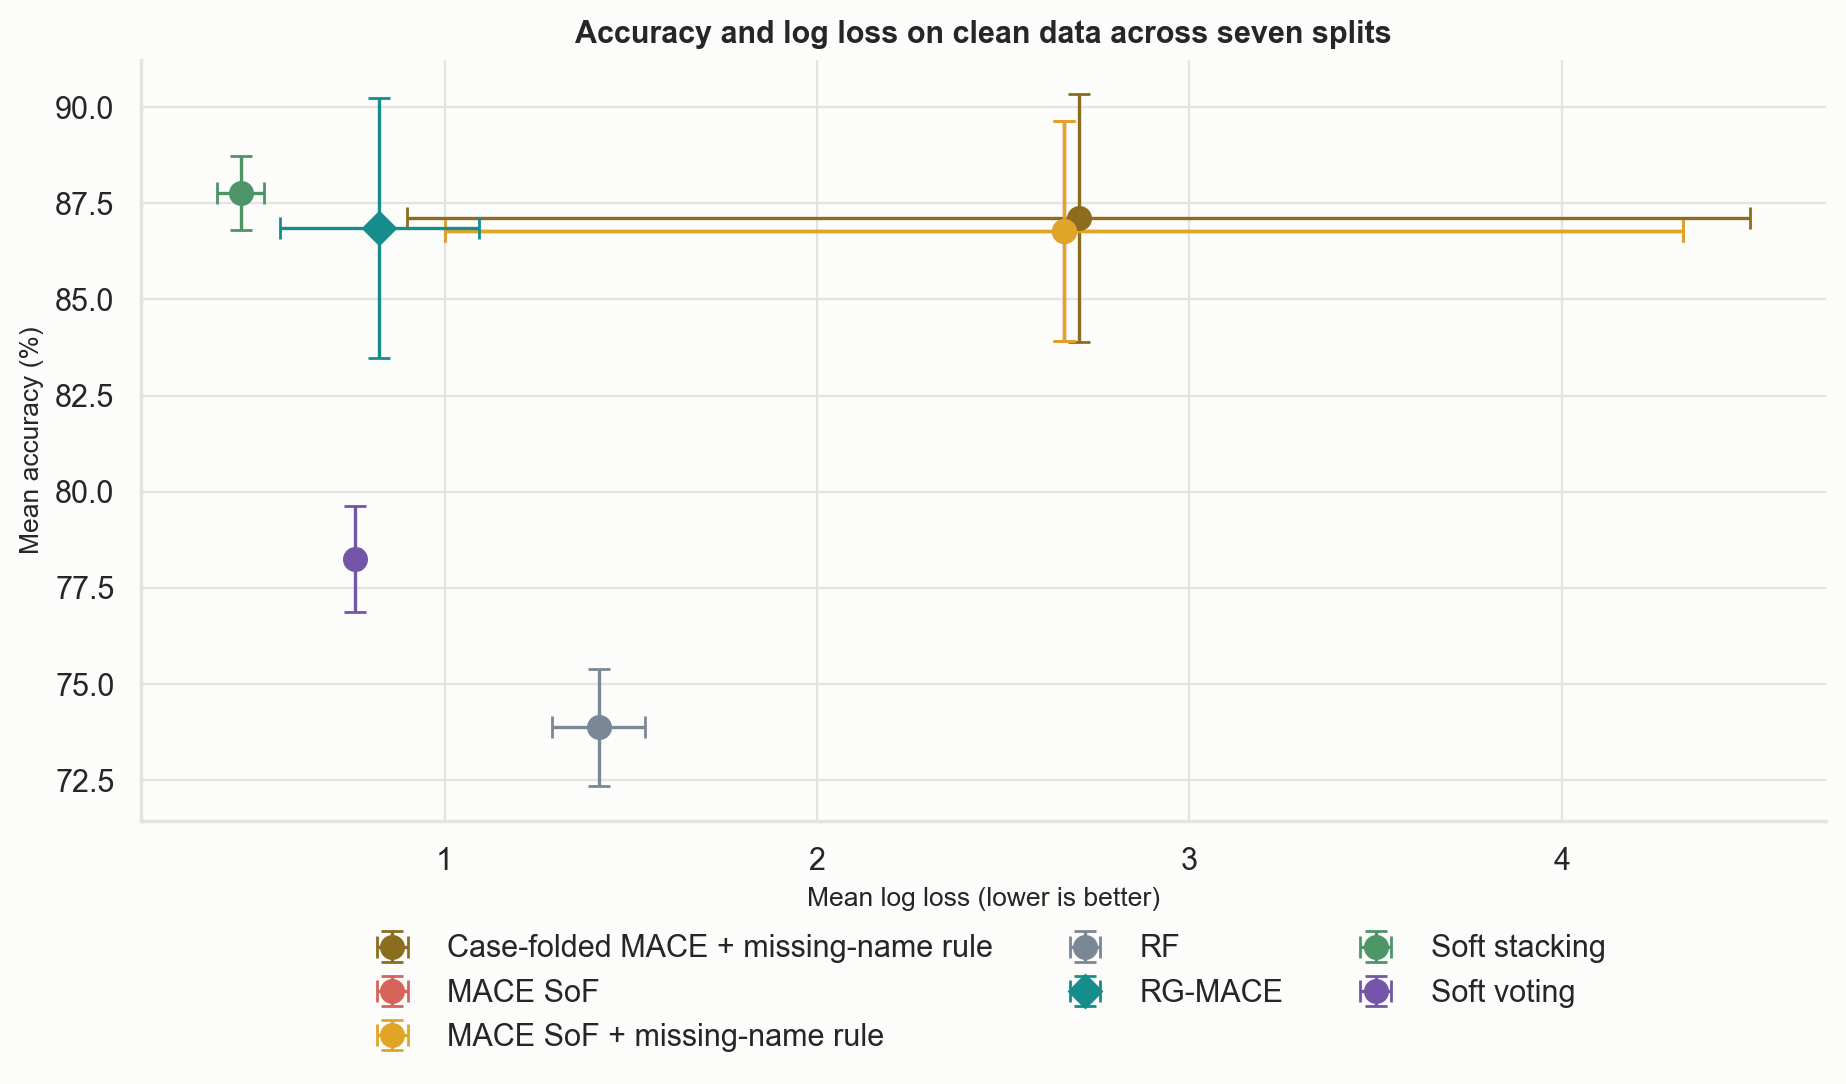

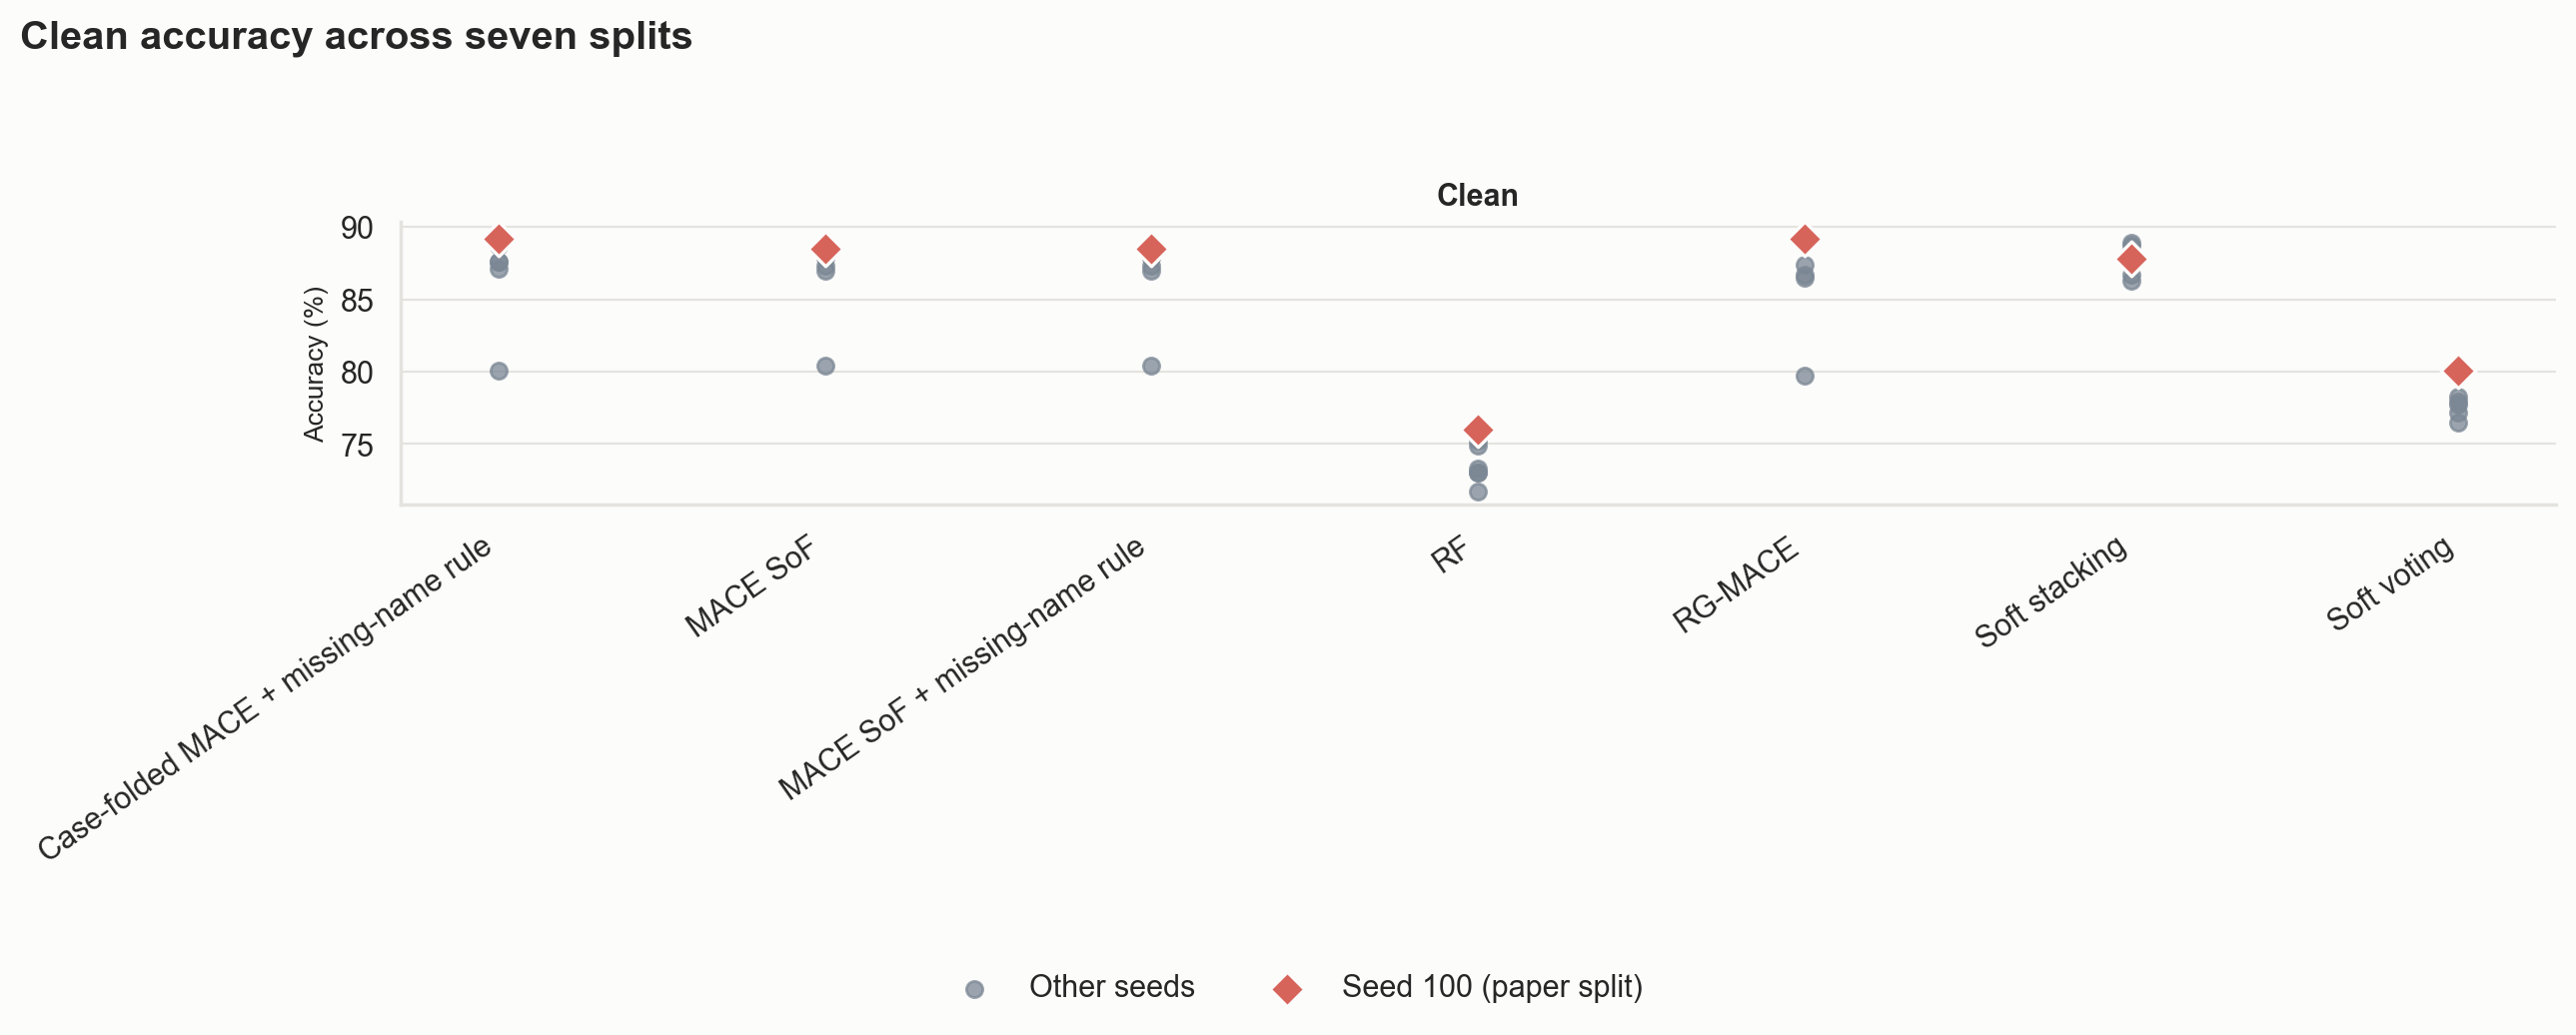

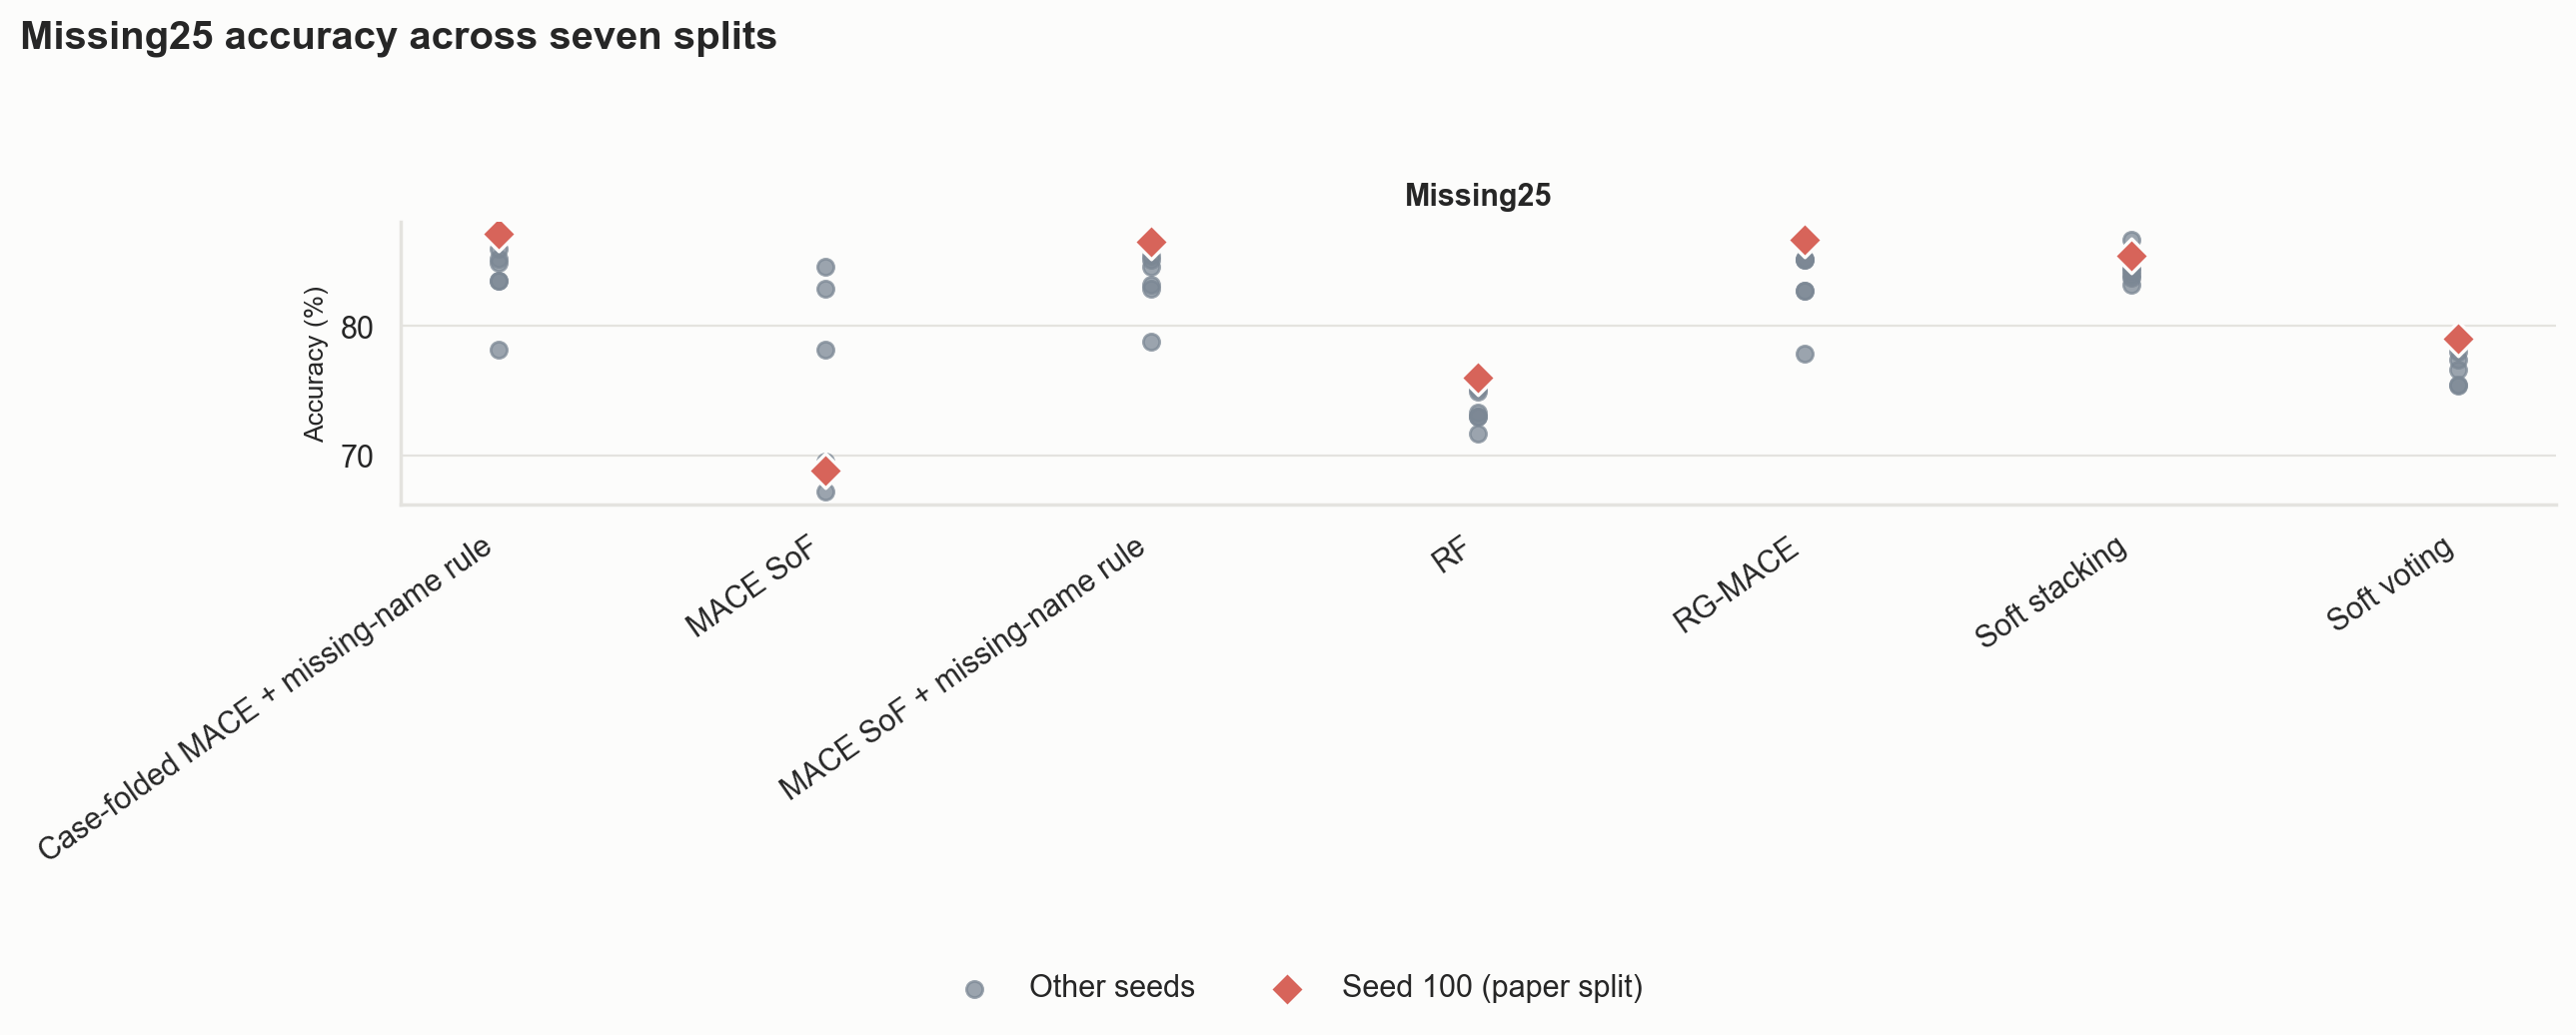

In [8]:
# measure clean and missing-name variation across seven splits
allTables['Exp28'] = runExp28RepeatedSplits(context)
display(allTables['Exp28']['summary'].round(2))
display(allTables['Exp28']['statistics'].round(3))
display(allTables['Exp28']['gateSelectionBySeed'].round(3))
display(Image(filename=str(PART2_FIGURES_DIR / 'accuracyCalibrationTradeoff.png')))
display(Image(filename=str(PART2_FIGURES_DIR / 'repeatedCleanAccuracy.png')))
display(Image(filename=str(PART2_FIGURES_DIR / 'repeatedMissingAccuracy.png')))

### Findings

- H1 is supported. Over seven splits RG-MACE averages 86.9% clean accuracy against 86.8% for MACE SoF and the 95% interval of the paired difference (-0.70 to +0.87) lies above the pre-registered -1 point margin
- Probability quality improves on every split. Mean log loss falls from 2.66 to 0.82 (paired difference -1.84, 95% CI -3.20 to -0.48, Wilcoxon p = 0.016) and Brier score by 0.020. The cost is macro F1, which is 2.0 points lower on average, although that interval crosses zero
- With 25% of names missing, RG-MACE averages 83.6% against 74.3% for MACE SoF (+9.3 points, 95% CI +1.2 to +17.3), with AUC +9.7 points and log loss 6.0 lower
- Against the fair case-folded rule, RG-MACE is level on accuracy (-0.3 clean, -0.4 with missing names) and slightly lower on macro F1, but significantly better on AUC (+3.9, p = 0.016) and log loss (-1.88, p = 0.016). The learned gate therefore adds calibrated, better-ranked probabilities rather than extra accuracy
- Generic soft stacking is the most stable method across splits (87.8% ± 1.0 against 86.9% ± 3.4 for RG-MACE) and has the best log loss (0.45). RG-MACE inherits MACE's weak split (seed 202, 79.7%) while stacking does not rely on the cascade. On the paper split RG-MACE is ahead of stacking on accuracy, macro F1 and every robustness curve
- The clean-F1 selection constraint was met on only 1 of the 7 splits. Six used the pre-specified fallback, with shortfalls from 0.02 to 1.46 points, which shows the 0.5-point constraint was too strict for this gate. In the accuracy and log-loss plot, MACE SoF sits exactly under "MACE SoF + missing-name rule" because they are identical on clean data

## Exp29: Ablation Study

Each component is removed or isolated on the seed-100 split. Clean data, unseen names, full missingness and primary robustness areas are reported, followed by corruption-share sensitivity. This checks whether the gain comes from the complete method rather than one simple rule

,Variant,CleanAccuracy,CleanF1,UnseenAccuracy,UnseenF1,Missing100Accuracy,MissingAccuracyAUC,CaseAccuracyAUC,DeleteAccuracyAUC,ReplaceAccuracyAUC
0,MACE SoF,88.5,79.4,78.9,61.2,12.6,69.92,85.04,87.97,88.17
1,MACE SoF + case folding,89.2,79.0,80.0,65.9,73.0,85.00,89.20,88.33,88.46
2,MACE SoF + missing-name rule,88.5,79.4,78.9,61.2,76.0,85.44,85.04,88.10,88.17
3,Case-folded MACE + missing-name rule,89.2,79.0,80.0,65.9,76.0,85.87,89.20,88.33,88.46
4,RG-MACE (hard gate),88.4,77.8,78.6,62.8,76.0,85.20,88.40,87.04,86.88
5,"RG-MACE, clean-trained gate",88.5,77.5,79.3,64.5,75.0,85.15,88.50,87.52,87.46
6,"RG-MACE, no class balancing",89.5,78.8,80.7,65.0,75.2,85.96,89.50,88.68,88.75
7,"RG-MACE, no name-distance features",89.2,78.8,80.0,64.7,74.6,85.44,89.20,88.25,88.11
8,"RG-MACE, no confidence features",89.5,79.0,80.7,65.5,75.4,86.01,89.50,88.74,88.64
9,"RG-MACE, case-sensitive",89.2,79.8,80.4,61.2,75.5,85.87,87.15,88.49,88.73


,CorruptionShare,CleanAccuracy,CleanF1,UnseenAccuracy,MissingAccuracyAUC
0,0.00,88.5,77.5,79.3,85.15
1,0.25,88.5,76.4,79.3,85.33
2,0.50,89.2,78.8,80.0,85.74
3,1.00,89.3,78.9,80.4,85.89


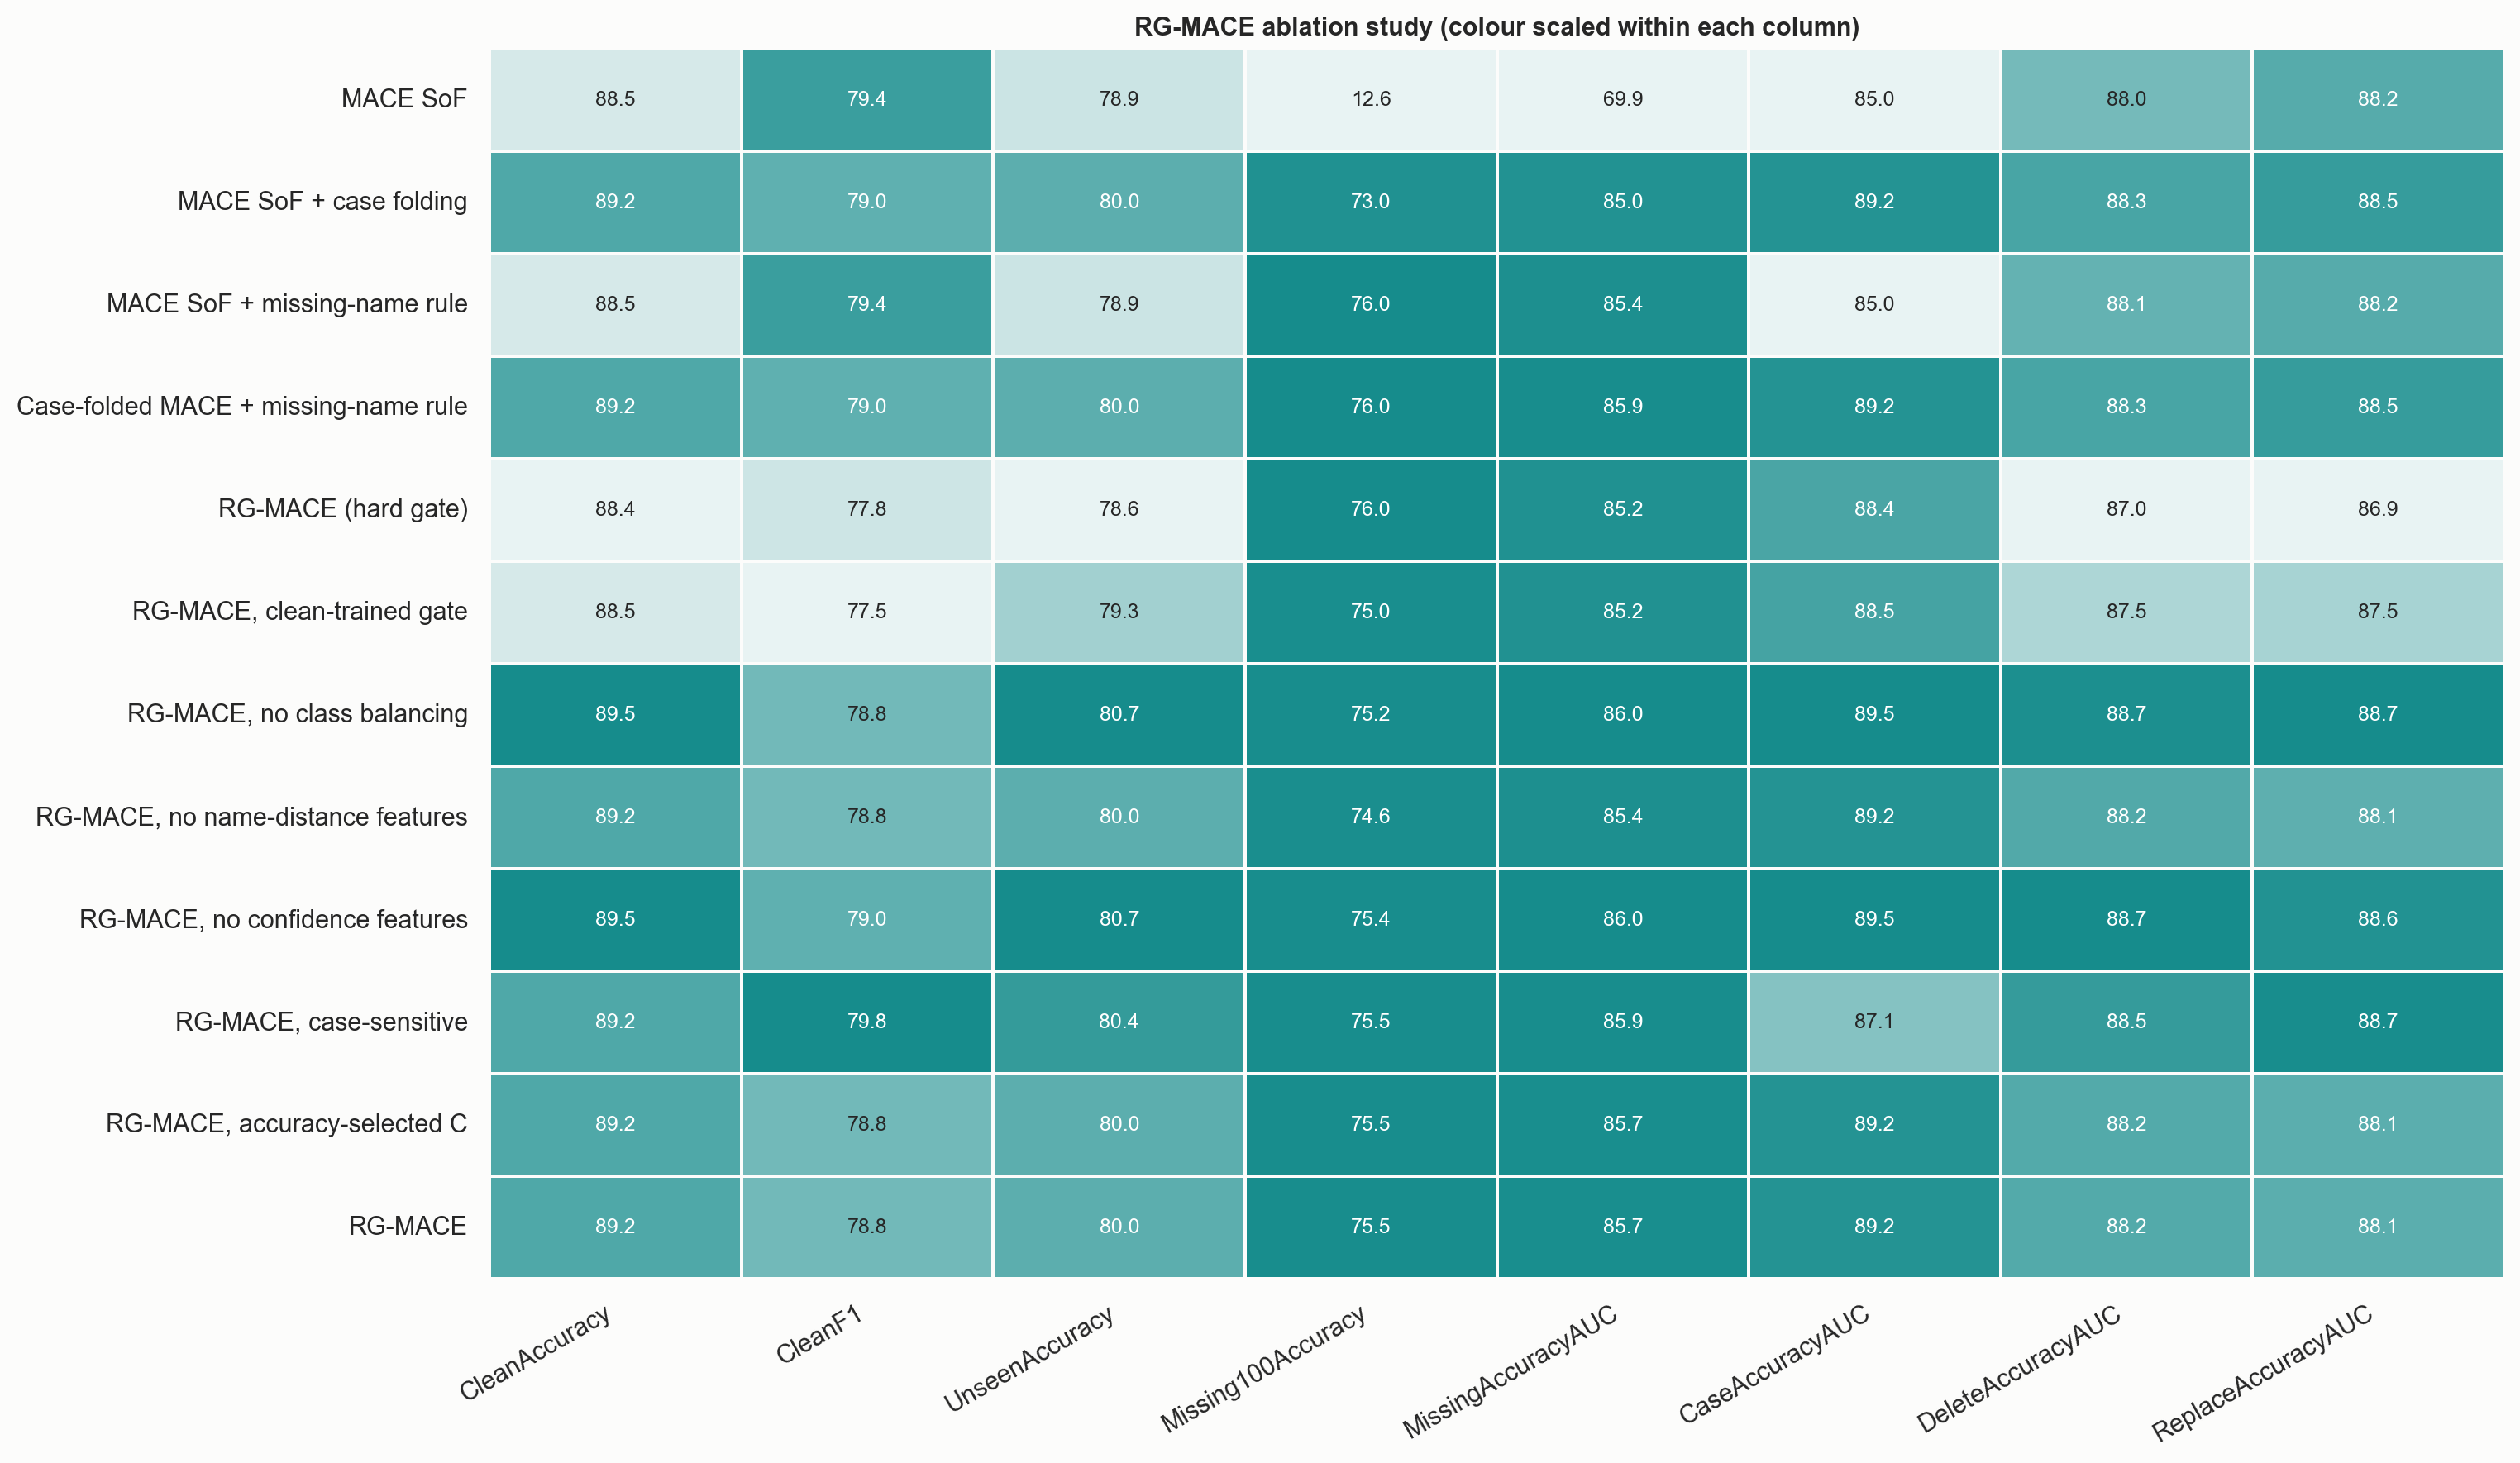

In [9]:
# isolate case folding soft fusion weighting features and augmentation
allTables['Exp29'] = runExp29Ablation(context)
display(allTables['Exp29']['ablation'].round(2))
display(allTables['Exp29']['corruptionShare'].round(2))
display(Image(filename=str(PART2_FIGURES_DIR / 'ablationStudy.png')))

### Findings

- The ablation separates the three ingredients of the improvement. Case folding alone raises clean accuracy to 89.2% and removes the case failure (89.2% case area). The missing-name rule alone removes the missing-name collapse (76.0% with all names missing). Together they already match RG-MACE on accuracy
- The learned gate is what removes the need for a hand-written rule. Every RG-MACE variant keeps 74.6 to 75.5% with all names missing, although none is told which names are missing
- Soft fusion beats hard routing: the hard-gate variant is lower on clean accuracy (88.4% against 89.2%), macro F1 (77.8 against 78.8) and every corruption area
- Training on corrupted copies helps. The clean-trained gate loses 0.7 points of clean accuracy and 1.3 of macro F1 and more corruption in training improves results steadily (missing-name area 85.2 with no copies, 85.9 with a copy of every row)
- Two pre-fixed design choices were not optimal. Removing class balancing or the confidence features slightly improves clean accuracy (89.5%) and unseen-name accuracy (80.7%). These are reported as found, not adopted after the fact, because adopting them would tune the method on the test set

## Exp30: Error Analysis, Statistical Evidence and Cost

This examines rare-class behaviour, corrected and broken errors, McNemar tests, stratified paired bootstrap intervals, calibration and computational cost. Gate-only fitting, supporting preparation and prediction cost are kept separate

,Method,Class,Precision,Recall,F1,Support,RareClass
0,MACE SoF,0,0.743,0.650,0.693,80,False
1,MACE SoF,1,0.955,0.985,0.970,130,False
2,MACE SoF,2,1.000,0.988,0.994,80,False
3,MACE SoF,3,0.796,0.901,0.845,91,False
4,MACE SoF,4,0.870,0.931,0.900,101,False
5,MACE SoF,5,0.917,0.786,0.846,14,False
6,MACE SoF,6,1.000,0.846,0.917,13,False
7,MACE SoF,7,0.667,0.500,0.571,4,True
8,MACE SoF,8,0.667,0.800,0.727,5,True
9,MACE SoF,9,0.000,0.000,0.000,1,True


,Condition,Comparison,AOnlyCorrect,BOnlyCorrect,Discordant,PValue
0,Clean,RG-MACE vs MACE SoF,16,20,36,0.6177
1,Clean,RG-MACE vs MACE SoF + missing-name rule,16,20,36,0.6177
2,Missing25,RG-MACE vs MACE SoF,20,134,154,0.0000
3,Missing25,RG-MACE vs MACE SoF + missing-name rule,12,13,25,1.0000


,Condition,Comparison,Metric,ObservedDifference,Lower95,Upper95,ProbabilityDifferenceAtMostZero
0,Clean,RG-MACE - MACE SoF,Accuracy,0.6279,-1.0989,2.5118,0.2660
1,Clean,RG-MACE - MACE SoF,F1,-0.5345,-5.1385,2.8977,0.6375
2,Clean,RG-MACE - MACE SoF,LogLoss,-1.2016,-1.7773,-0.6527,1.0000
3,Unseen,RG-MACE - MACE SoF,Accuracy,1.0526,-2.4561,4.5614,0.3095
4,Unseen,RG-MACE - MACE SoF,F1,0.2365,-5.9197,5.8057,0.4905
5,Unseen,RG-MACE - MACE SoF,LogLoss,-2.2231,-3.2314,-1.2838,1.0000
6,Missing25,RG-MACE - MACE SoF,Accuracy,17.8964,14.5997,21.1931,0.0000
7,Missing25,RG-MACE - MACE SoF,F1,6.8052,3.7460,10.4165,0.0000
8,Missing25,RG-MACE - MACE SoF,LogLoss,-8.8098,-9.9702,-7.6142,1.0000
9,Unseen,RG-MACE - missing-name rule,Accuracy,1.0526,-2.4561,4.5614,0.3095


,Method,LogLoss,BrierScore
0,MACE SoF,2.0252,0.1998
1,RG-MACE,0.8236,0.1802


,Component,Seconds,MillisecondsPerStream,ModelBytes
0,Part 1 preparation and OOF pool scores,101.8736,NaN,NaN
1,MACE expert fitting and reselection,21.0838,NaN,NaN
2,OOF gate dataset construction,4.7211,NaN,NaN
3,Gate selection and final fitting,0.3419,NaN,2062.0
4,MACE SoF prediction,7.4758,11.736,NaN
5,RG-MACE prediction,6.9815,10.960,NaN


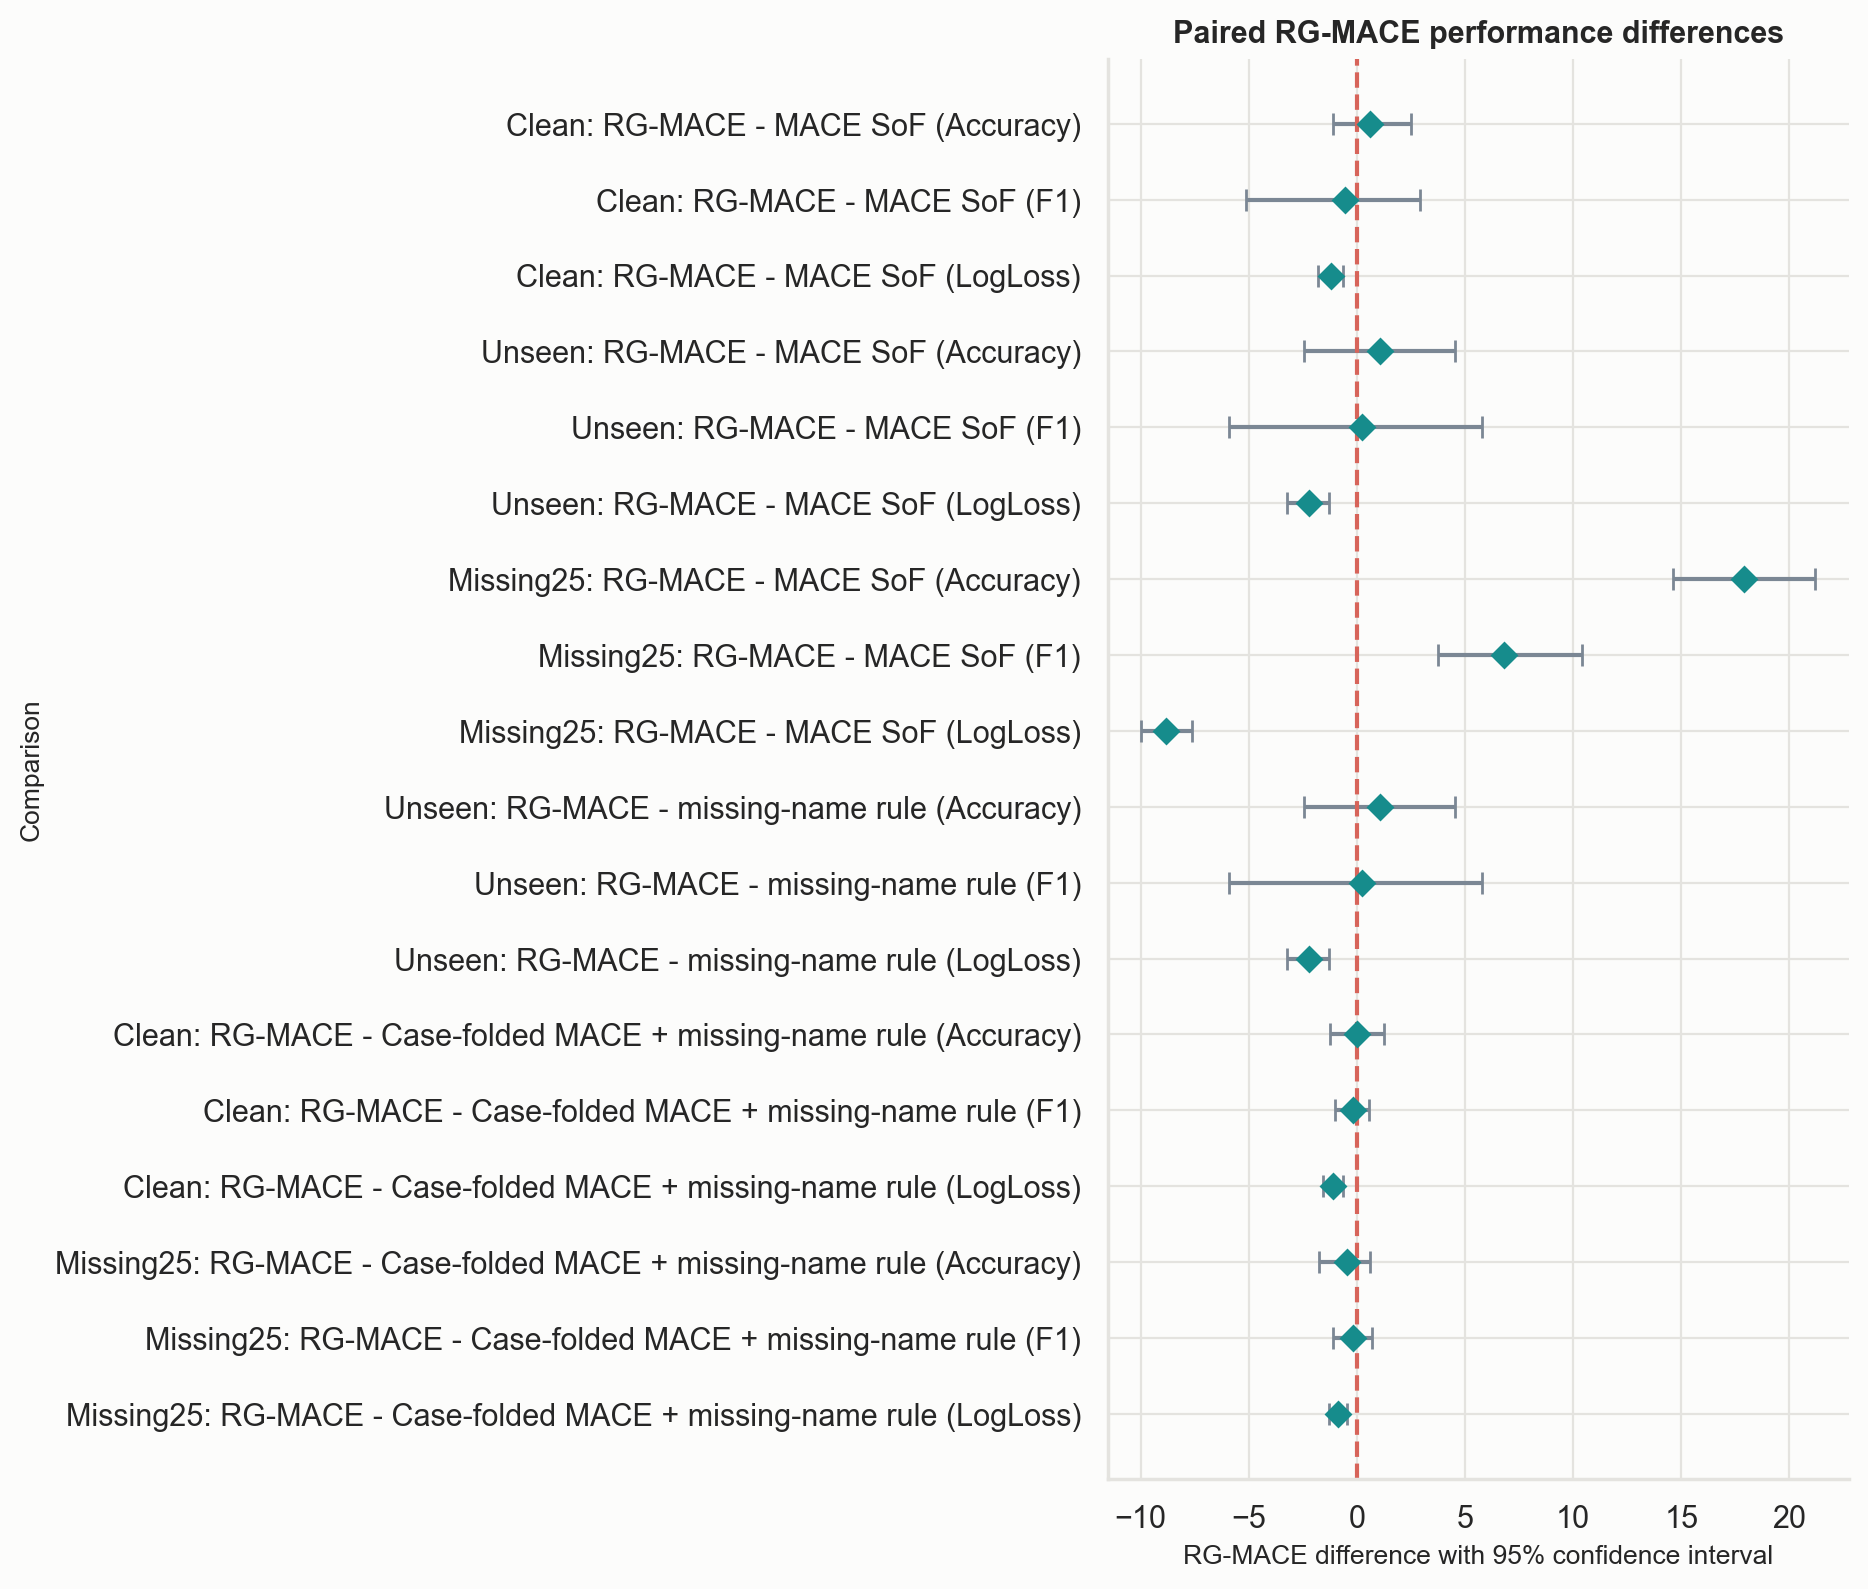

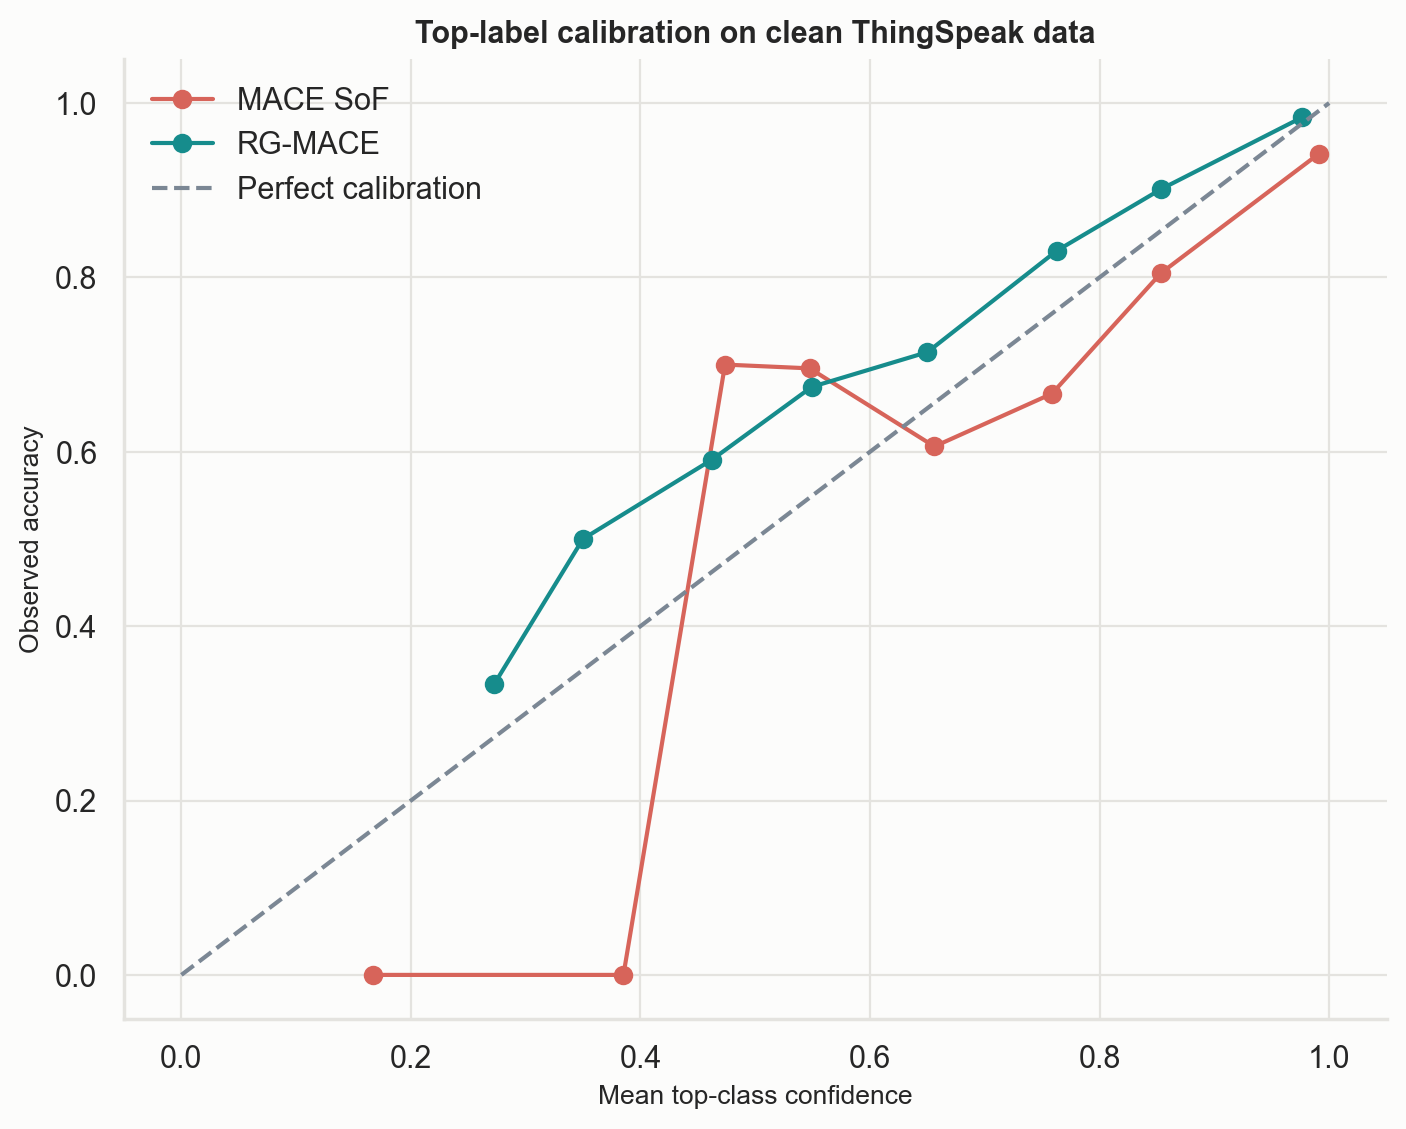

In [10]:
# produce the final error statistical calibration and cost evidence
allTables['Exp30'] = runExp30EvidenceAndCost(context)
display(allTables['Exp30']['perClass'].round(3))
display(allTables['Exp30']['mcnemar'].round(4))
display(allTables['Exp30']['bootstrap'].round(4))
display(allTables['Exp30']['calibration'].round(4))
display(allTables['Exp30']['cost'].round(4))
display(Image(filename=str(PART2_FIGURES_DIR / 'pairedDifferenceForest.png')))
display(Image(filename=str(PART2_FIGURES_DIR / 'reliabilityDiagram.png')))

### Findings

- On clean data RG-MACE and MACE SoF are statistically indistinguishable in accuracy (McNemar: 20 against 16 discordant streams, p = 0.62.. bootstrap difference +0.6 points, 95% CI -1.1 to +2.5) while log loss is clearly better (-1.20, 95% CI -1.78 to -0.65)
- With 25% of names missing the improvement is decisive: RG-MACE is right on 134 streams that MACE gets wrong and wrong on only 20 that MACE gets right (p < 0.0001), with +17.9 points of accuracy (95% CI +14.6 to +21.2) and +6.8 points of macro F1 (95% CI +3.7 to +10.4)
- Against the case-folded rule, accuracy and macro F1 differences are within about half a point and their intervals include zero while log loss is better on clean data (-1.09) and with missing names (-0.85), with both intervals excluding zero
- The per-class table shows the source of the small macro-F1 cost: some rare classes with three to five test streams lose a correct prediction (for example classes 11 and 13) while others gain one (class 8). With so few streams, each change moves a class F1 by 0.2 or more
- The method is cheap. Gate data construction takes 4.7 s and gate selection 0.3 s, against about 102 s for the shared Part 1 preparation. The gate model is 2 KB and prediction with empty caches takes 11.0 ms per stream against 11.7 ms for MACE SoF so the overhead criterion is met

## Hypotheses and success criteria: verdict

In [11]:
# evaluate the fixed targets from the generated evidence
successCriteria = runPart2SuccessCriteria(allTables)
display(successCriteria)

,Criterion,Target,ObservedValue,Met,Detail
0,Clean accuracy at seed 100,>= 88.0%,89.200000,True,
1,Clean macro F1 at seed 100,>= 78.9%,78.800000,False,
2,Seven-seed clean non-inferiority,Lower 95% bound > -1 point,-0.701634,True,
3,Clean log loss,Better than MACE SoF,-1.201600,True,
4,Clean Brier score,Better than MACE SoF,-0.019578,True,
5,Unseen-name accuracy,Lower paired seed CI above 0,-0.765829,False,
6,Unseen-name macro F1,Lower paired seed CI above 0,-5.282678,False,
7,25% missing names,>= MACE SoF + 5 points,15.933333,True,
8,100% missing names,>= 74.0%,75.500000,True,
9,Primary corruption AUC,Higher for all four modes,-0.045000,False,missing: +15.83; case: +4.16; delete: +0.27; r...


Ten of the sixteen pre-registered criteria are met.

| Hypothesis | Verdict | Key evidence |
|---|---|---|
| H1 - clean non-inferiority | Supported | 7-split accuracy difference -0.70 to +0.87 (margin -1).. log loss 2.66 to 0.82.. seed-100 accuracy 89.2% (macro F1 78.8, 0.1 below its target) |
| H2 - unseen names | Not supported | 79.3% against 79.1%.. unseen names still carry useful signal for MACE (79.1% against 71.1% for RF) |
| H3 - missing and corrupted names | Largely supported | Missing +15.8, case +4.2 and delete +0.3 area points.. replace -0.05 (tie).. 75.5% with all names missing |
| H4 - learned gate against the rule | Partly supported | Not worse than the rule on missing names (+0.3).. ahead on case and delete.. tie on replace and unseen names.. against the case-folded rule its advantage is probability quality (AUC +3.9, log loss -1.88 over 7 splits) |
| H5 - leakage-controlled | Supported | Channel split: clean +0.4, 25% missing +13.9, log loss 0.47 against 2.20 |

**Conclusion**

- RG-MACE solves the limitation identified in Part 1
- It keeps MACE's clean accuracy while removing the collapse under missing names and the poor calibration caused by hard class elimination and this holds across seven splits and a channel-grouped split
- The analysis also shows where the improvement comes from: case folding handles formatting, falling back to the numerical expert handles missing names and the learned soft gate provides both of these without a hand-written rule while adding much better-calibrated probabilities
- The hypothesis that unseen names are a failure case was not supported and generic soft stacking proved a strong alternative across splits